# What TM scattering sees of a microstructure: the average, an exact second-order term, the termination, and the detectability law

A medium whose structure is finer than the wavelength is replaced, in a scattering experiment, by a homogeneous one. This notebook asks what the replacement keeps, what it loses, and how a Bayesian estimate of the replacement's parameters reacts to the loss. The setting is the TM testbed of this repository (E along $z$, $\lambda_0=1$, 40 transmitters at radius 4 and 60 receivers at radius 4.5, 30 dB noise), where the object is a disk of radius $R_D=1$ whose interior is a microstructure of period $p$ and the model is a homogeneous disk $(\varepsilon,R)$ with the exact Mie data. The answer is organized by order in $p$: the average $\langle\varepsilon\rangle$ is what the data see at leading order; a second-order term, exact in the contrast, is the only trace of the bulk microstructure in the effective permittivity; at first order in the data the bulk does not appear at all below a period of $\lambda_0/2$, only the boundary does; and the way a layered structure *ends* acts at $O(p)$ as a radius shift that the homogeneous fit absorbs without a trace in the misfit, while at $O(p^2)$ the boundary terms (at the outer boundary and at the center) shift the fitted permittivity by an amount comparable to the bulk term, of either sign.

The reason to care is the detectability law of `docs/DESIGN.md` section 15: a model error $\delta$ splits into a part inside the tangent space of the model, which biases the parameters (measured in posterior standard deviations as $z$), and a part orthogonal to it, which only raises the misfit by $\Delta\Phi$ (in nats), with $c=\Delta\Phi/z^2$ fixed by the direction of $\delta$. Whether a given microstructure is *caught* (by a $\chi^2$ flag on the misfit), *absorbed* (a radius shift) or *reported as a different composition* is then a question about which of these parts it feeds. The main result of section 3 below, in the form the evidence supports: for rings the homogeneous fit reports $\varepsilon_{\rm eff}(k_0)=\langle\varepsilon\rangle+{\rm Rytov}$, not the volume average $\langle\varepsilon\rangle$, before the layering is detectable in the misfit; the fitted shift also carries a boundary term of either sign at $O(p^2)$, so it is not a clean measurement of the bulk term. Every computation below uses exact references: a multilayer Mie series for rings, the Mie disk with analytic tangents for the model, the plane-wave expansion of `bloch.py` for lattices, and the testbed forward solver for the one place where no closed form exists (a lattice of rods).

## What this notebook shows

- **Section 1.** For a lattice in TM, $\varepsilon_{\rm eff}(k_0)=\langle\varepsilon\rangle+k_0^2S+O(k_0^4)$ with $S=\sum_{\mathbf G\ne0}|\hat\varepsilon_{\mathbf G}|^2/|\mathbf G|^2$, positive and exact in the contrast; for a lattice with a $C_4$ axis the $k_0^2$ and $k_0^4$ coefficients are isotropic and direction dependence first appears at $O(k_0^6)$ as $\cos4\phi$. In 1D it is Rytov's formula (agreement $7\times10^{-16}$). For rods of radius $0.3a$ the sum is $1.28744$ ($\varepsilon=4$) and $17.30895$ ($\varepsilon=12$) in $(a/\lambda)^2$ over about 600 plane waves; the truncation error falls as $G_{\max}^{-3}$ (ratios of successive increments $7.46$ to $7.90$, against 8), which extrapolates to $1.28755$ and $17.31042$; the first $\mathbf G$-shell carries $0.851$ of the 600-wave sum. The plane-wave band computation reproduces the $k_0^2$ coefficient to $1.4\times10^{-4}$ and $1.55\times10^{-4}$, gives a $k_0^4$ residual coefficient that is constant between $K a=0.1$ and $0.2$ to $0.2\%$ and $0.4\%$, and the difference of that coefficient between $\Gamma X$ and $\Gamma M$ grows by $4.38$ and $4.43$ per doubling of $K$ (4 predicted for $\cos4\phi$ at $k_0^6$).
- **Section 2.** Ring-aperture Born data see an object's spatial spectrum only inside a disk of radius $2k_0$. Gratings under a Gaussian window show a gain of $0.63$ at 2 cycles per wavelength and $0.0024$ at 3 (ratio $0.0035$ to the gain at 1.5 cycles), and a spectral prediction computed from the sampled object reproduces the measured gain within $5\%$ over four decades. The domain of side 2.5 first planned (PLAN.md) cuts the window and leaks: its ratio is $0.0179$, not below the expected $10^{-2}$. A hard-edged patch of the same grating has ratio $0.148$ ($n=64$) and $0.137$ ($n=128$), about 40 times the windowed ratio: at first order the boundary is what sees sub-wavelength structure.
- **Section 3.** *Termination.* For concentric rings the period cut moves the fitted radius by the predicted $-0.15p$ to within a relative deficit of $0.0267$ at $p=0.025$ and $0.0137$ at $p=0.0125$ (a deficit of $1.12p-2.25p^2$ on $n_p=10$ to $80$), while the mid-layer cut moves it by $O(p^2)$; raw error slopes are $1.000$ and $2.013$. *Law.* For the mid cut $z\propto p^{2.04}$, $\Delta\Phi\propto p^{4.04}$, the normal residual is at $18.01^\circ$ and $c=1.53$; the log-log windows are $p_{3\rm nat}=0.0318<p_z=0.0463<p_{\rm flag}=0.0840$ for the *integer-$n_p$ mid-cut family* (the evaluated range ends at $p=1/12$). Direct evaluation at $p=1/22,\,1/15,\,1/12$ gives $z=2.89,\,6.35,\,10.15$ and flag probabilities $0.003,\,0.040,\,0.498$; Monte Carlo gives $83/2000=0.0415$ at $p=1/15$ (exact 99% interval $[0.031,\,0.054]$) and $225/400=0.5625$ at $p=1/12$ ($[0.497,\,0.627]$, so the first-order $0.498$ sits at the edge; with the nonlinear misfit the prediction is $0.520$). *What the window means depends on the target.* (a) As an estimator of the volume average $\langle\varepsilon\rangle$ the fit is off by $0.80$ to $1.29$ times the Rytov term, which exceeds 3 sd from $p_z$. (b) As an estimator of $\varepsilon_{\rm eff}(k_0)=\langle\varepsilon\rangle+{\rm Rytov}$ the standardized error $(\Delta\varepsilon-{\rm Rytov})/{\rm sd}$ at $p=1/22,\,1/15,\,1/12$ is $-0.72,\,-1.41,\,-1.99$ for this structure and $+0.85,\,+2.03,\,+3.53$ for the layer-swapped one. So the fit reports $\varepsilon_{\rm eff}(k_0)$, not the volume average, before the layering is detectable. Reading (b) is not general: at $p=0.07$ ($n_p=14.29$, the structure of section 5) $z=4.63$, the flag probability is $0.113$ (not below $0.04$) and the errors against $\langle\varepsilon\rangle+{\rm Rytov}$ are $-3.93$ and $+4.68$ sd. *Even and odd parts.* **A first reading of the ratio $\Delta\varepsilon_{\rm fit}/{\rm Rytov}\approx0.78$, that the homogeneous fit fails to recover the bulk Rytov term, is not supported, and neither is the reading that the fit measures it.** Over 11 mid-cut structures (contrast, mean, $R_D$, core phase) the part of $\Delta\varepsilon_{\rm fit}$ that is even under swapping the layer permittivities is $1.0008$ to $1.0029$ times Rytov (relative deviation down by $3.92$ per halving of $p$). The odd part, linear in the contrast and $O(p^2)$, is not universal: it runs from $-0.656$ to $+0.708$ times Rytov, changes with the core phase at a fixed outer cut ($-0.213,\,-0.435,\,-0.656,\,-0.435$), the mean and $R_D$, so $\Delta\varepsilon_{\rm fit}/{\rm Rytov}$ ranges from $0.29$ to $1.71$ and the ratio $0.78$ (here $0.788$) is not a property of bulk homogenization. For the period cut the even part is $0.741$ for the base structure and runs from $0.737$ to $1.335$ over the structures.
- **Section 4.** For a square lattice of rods inside a disk, the data lie in the rotation sectors $Q_0\oplus Q_4\oplus Q_8$ of the 18-degree group to $4\times10^{-11}$, the model tangents lie in $Q_0\oplus Q_1$ to $3\times10^{-15}$, and the $Q_4\oplus Q_8$ part of the error (between $5\%$ and $36\%$ of $\|\delta\|^2$ in $Q_4$ and $20\%$ to $32\%$ in $Q_8$) is orthogonal to all four tangents ($3\times10^{-16}$); the nonlinear fit with and without that part agrees to $9\times10^{-11}$ posterior sd, and the misfit changes by exactly its $\Delta\Phi$. Fits started with the center displaced or with $(\varepsilon,R)$ displaced return to the same minimum to $7\times10^{-11}$ sd, so the symmetric point is a minimum and not only a stationary point of the symmetric subspace.
- **Section 5.** For rings with a random cut at $p=0.07$, the standardized bias of the composition is $3.4$ to $13.7$ sd (rms $8.8$) and the naive 90% interval covers $0.005$ of the held-out cases. Linearizing at the base point is wrong by up to $15.5$ sd for cuts that move the radius; at the profile foot point it agrees with the nonlinear fit to $0.025$ sd. The approximation-error model (AEM) in the foot frame gives held-out coverage $0.897$ on a random split, but that number cannot fail: four training cuts already give $0.897$. Discriminating tests: trained on half of the cut interval and tested on the other half the AEM has rms $z$ of $0.21$ and $0.88$ (coverage $0.893$ and $0.774$), trained on the outer quarters and tested on the middle (or the reverse) $0.64$ and $0.55$; trained at $p=0.07$ and tested at $p=0.06$ and $0.08$ it has rms $z=2.4$ and $2.5$ and coverage $0.30$ and $0.31$; tested at half the contrast it is worse than no correction (rms $z$ $5.96$ against $2.75$). The AEM transfers across the one-parameter family it was trained on and not across period or contrast.

## Conventions

Time dependence $e^{-i\omega t}$; TM means $E=E_z$ along the invariant axis. Lengths are in units of $\lambda_0=1$ ($k_0=2\pi$) in the testbed sections (2 to 5), and in units of the period $a$ in the band computations of section 1. $\varepsilon$ is the relative permittivity, $\chi=\varepsilon-1$ the contrast. Data are $(N_t,N_r)=(40,60)$ complex arrays; whitening is $\sqrt2/s\,[\operatorname{Re};\operatorname{Im}]$ with $s^2$ the mean $|d|^2$ times $10^{-3}$ (30 dB), so $\Phi=\tfrac12\|r_w\|^2$ in nats and the number of real data is $4800$. $z=(\text{fitted}-\text{base})/\sigma$ as in `detectability.analyze_error`; $\Delta\Phi=\tfrac12\|P_\perp\delta\|^2$; $\alpha$ is the angle of $\delta$ to the tangent space and $c=\Delta\Phi/z^2=\tfrac12\tan^2\alpha/\cos^2\beta$. The flag level is $3\sqrt{2400}=146.97$ nats, three standard deviations of $\Phi$ for 2400 complex data. "Rytov" below means the second-order correction $k_0^2p^2f^2(1-f)^2\Delta\varepsilon^2/12$ (the correction, not $\varepsilon_{\rm eff}$). Band indices and the plane-wave truncation follow `bloch.py` (about 600 plane waves in a circular cutoff).

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported
os.environ.setdefault("NPROC", "4")  # size of the XLA CPU thread pool (never 2: see scripts/batch_run.py)
os.environ.setdefault("XLA_FLAGS", "--xla_cpu_multi_thread_eigen=" + ("false" if os.environ["NPROC"] == "1" else "true"))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

# Figure style shared by every notebook in notebooks/homogenization (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name


def check_in(name, value, lo, hi):
    """Print PASS or FAIL for lo <= value <= hi (a bound, an interval, a sign) and assert it."""
    ok = lo <= value <= hi
    print(f"{'PASS' if ok else 'FAIL'}  {name}: got {value:.6g}, required in [{lo:.6g}, {hi:.6g}]")
    assert ok, name

In [2]:
import sys, pathlib, time
from matplotlib.ticker import NullFormatter
T0 = time.perf_counter()                               # run time is printed at the end
sys.path.insert(0, str(pathlib.Path.cwd()))            # scatter.py and bloch.py sit next to this notebook
import scatter as sc
import bloch as bl
from scipy import stats, special
from bayes_scatter import detectability as det
from bayes_scatter.forward import Forward
from bayes_scatter.geometry import ch15_setup, ring
from bayes_scatter.phantoms import cylinder

tx, rx = ring(40, 4.0), ring(60, 4.5)                  # the ch15 acquisition: 40 transmitters at radius 4, 60 receivers at radius 4.5
N_DATA = tx.shape[0] * rx.shape[0]                     # 2400 complex data
FLAG = sc.flag_nats(N_DATA)                            # 3 sd of the chi^2 misfit, in nats
print(f"{N_DATA} complex data (= {2 * N_DATA} real), flag level 3 sqrt({N_DATA}) = {FLAG:.2f} nats")


def rel(a, b):
    """Relative l2 distance."""
    return float(np.linalg.norm(np.asarray(a) - np.asarray(b)) / np.linalg.norm(b))


def table(header, rows, fmts):
    """Print an aligned table; fmts are format specs per column."""
    cells = [[f"{v:{fm}}" if not isinstance(v, str) else v for v, fm in zip(r, fmts)] for r in rows]
    w = [max(len(h), *(len(c[i]) for c in cells)) for i, h in enumerate(header)]
    print("  ".join(h.rjust(w[i]) for i, h in enumerate(header)))
    for c in cells:
        print("  ".join(c[i].rjust(w[i]) for i in range(len(header))))

2400 complex data (= 4800 real), flag level 3 sqrt(2400) = 146.97 nats


## 1. TM homogenization: an average plus an exact second-order term

In a $z$-invariant medium $E_z=u$ is tangential at every interface, so $u$ and $\partial_nu$ are continuous and the TM equation is $-\Delta u=k_0^2\varepsilon(\mathbf r)u$ with the material only in the coefficient. For Bloch waves $u=e^{i\mathbf K\cdot\mathbf r}\sum_{\mathbf G}p_{\mathbf G}e^{i\mathbf G\cdot\mathbf r}$ and $\varepsilon=\sum\hat\varepsilon_{\mathbf G}e^{i\mathbf G\cdot\mathbf r}$,

$$|\mathbf K+\mathbf G|^2p_{\mathbf G}=k_0^2\sum_{\mathbf G'}\hat\varepsilon_{\mathbf G-\mathbf G'}\,p_{\mathbf G'} .$$

Take the lowest band, $p_0=1$, and let $K\sim k_0\to0$. For $\mathbf G\neq0$ the left side is $|\mathbf G|^2(1+O(K))$, so $p_{\mathbf G}=k_0^2\hat\varepsilon_{\mathbf G}/|\mathbf K+\mathbf G|^2+O(k_0^4)$. Row $\mathbf G=0$ then gives

$$\varepsilon_{\rm eff}:=\frac{|\mathbf K|^2}{k_0^2}=\langle\varepsilon\rangle+k_0^2\sum_{\mathbf G\neq0}\frac{|\hat\varepsilon_{\mathbf G}|^2}{|\mathbf K+\mathbf G|^2}+O(k_0^4),\qquad |\mathbf K+\mathbf G|^{-2}=|\mathbf G|^{-2}-2\frac{\mathbf K\cdot\mathbf G}{|\mathbf G|^4}+\dots$$

The term linear in $\mathbf K$ is odd in $\mathbf G$ while $|\hat\varepsilon_{\mathbf G}|^2$ is even (real $\varepsilon$ gives $\hat\varepsilon_{-\mathbf G}=\overline{\hat\varepsilon_{\mathbf G}}$), so it cancels, and

$$\boxed{\;\varepsilon_{\rm eff}=\langle\varepsilon\rangle+k_0^2S+O(k_0^4),\qquad S=\sum_{\mathbf G\neq0}\frac{|\hat\varepsilon_{\mathbf G}|^2}{|\mathbf G|^2}=\big\langle|\nabla\Delta^{-1}(\varepsilon-\langle\varepsilon\rangle)|^2\big\rangle_{\rm cell}\;}$$

(the cell average of the squared gradient of the periodic potential of $\varepsilon-\langle\varepsilon\rangle$: its $\dot H^{-1}$ norm). Conditions and consequences. (i) Nothing is assumed small: the expansion is in $k_0a$ and $S$ is exact in the contrast; for rods in a background $\hat\varepsilon_{\mathbf G}\propto\varepsilon_{\rm rod}-1$, so $S\propto(\varepsilon_{\rm rod}-1)^2$ exactly. (ii) $S>0$, so $\varepsilon_{\rm eff}>\langle\varepsilon\rangle$. (iii) The $K^2$ term is a scalar: there is no $O(p^2)$ anisotropic spatial-dispersion tensor in TM. The $O(k_0^4)$ term of $\varepsilon_{\rm eff}$ is built from a rank-2 tensor, so for a lattice with a $C_4$ axis (square) or a $C_3$ axis (hexagonal) it is also isotropic, and the first direction dependence of a square lattice is the $\cos4\phi$ term at $O(k_0^6)$; for a lattice of lower symmetry it appears at $O(k_0^4)$ (not computed here). (iv) In 1D $\nabla\Delta^{-1}$ is the antiderivative, $S$ is the variance of the triangle wave $\int(\varepsilon-\langle\varepsilon\rangle)$ of peak-to-peak height $p f(1-f)\Delta\varepsilon$, and $k_0^2S=k_0^2p^2f^2(1-f)^2\Delta\varepsilon^2/12=(\pi^2/3)(p/\lambda)^2f^2(1-f)^2\Delta\varepsilon^2$: Rytov's ordinary-wave correction for $\mu=1$.

The cells below sum the 1D series directly (with the $n^{-4}$ tail) against the closed form, evaluate $S$ for a square lattice of disks ($R=0.3a$) from the Fourier coefficients of `bloch.eps_hat`, and compare with the lowest band of the plane-wave solver at small $\mathbf K$ along $\Gamma X$ and $\Gamma M$. The solver's units are $a=1$, so $k_0=2\pi f$ with $f=a/\lambda$, and the coefficient of $(a/\lambda)^2$ is $(2\pi)^2S$ (the values 1.2874 and 17.309 expected in PLAN.md are these sums over about 600 plane waves; the converged values are slightly larger).

In [3]:
# 1D laminate: the second-order sum against Rytov's closed form
rows = []
for f_, e1_, e2_, p_ in ((0.5, 3.0, 1.5, 0.1), (0.3, 4.0, 1.0, 0.2), (0.7, 12.0, 1.0, 0.05)):
    s_sum, s_cf = sc.tm_second_order_1d(f_, e1_, e2_, p_), sc.rytov_tm(f_, e1_, e2_, p_)
    rows.append((f_, e1_, e2_, p_, s_sum, s_cf, abs(s_sum / s_cf - 1)))
table(["f", "eps1", "eps2", "p", "direct sum", "Rytov", "rel diff"], rows, [".1f", ".1f", ".1f", ".2f", ".6e", ".6e", ".1e"])
check("1D second-order sum vs Rytov closed form, max rel over 3 laminates", max(r[-1] for r in rows), 1e-10)

  f  eps1  eps2     p    direct sum         Rytov  rel diff
0.5   3.0   1.5  0.10  4.626377e-03  4.626377e-03   6.7e-16
0.3   4.0   1.0  0.20  5.222995e-02  5.222995e-02   2.2e-16
0.7  12.0   1.0  0.05  4.388766e-02  4.388766e-02   2.2e-16
PASS  1D second-order sum vs Rytov closed form, max rel over 3 laminates: got 6.66134e-16, target 0, |diff| 6.66e-16 <= 1e-10


In [4]:
# 2D: square lattice of disks, R = 0.3 a, eps = 4 and 12; the sum over G of |eps_G|^2/|G|^2
sq = bl.Lattice.square(1.0)
GM = bl.gmax_for_count(sq, 600)
G600, _ = bl.gvectors(sq, GM, 0)
PW = {}
rows = []
for eps_r in (4.0, 12.0):
    rods = [bl.disk((0, 0), 0.3, eps_r)]
    S600 = sc.tm_second_order_sum(sq, rods, GM)                       # in (a/lambda)^2
    S1 = sc.tm_second_order_sum(sq, rods, 2 * np.pi * 1.0001)         # first shell only (4 vectors, |G| = 2 pi)
    Sk = sc.tm_second_order_sum(sq, rods, GM, units="k0")
    avg = float(np.real(bl.eps_hat(sq, rods, np.zeros((1, 2)))[0]))
    PW[eps_r] = dict(rods=rods, S600=S600, S1=S1, Sk=Sk, avg=avg, B=bl.eps_matrix(sq, rods, G600))
# truncation study: circular cutoff |G| <= 2 pi m; |eps_G|^2 ~ G^-3 on average for a sharp edge, so the summand is ~ G^-5 and the tail of the 2D sum (area element G dG) falls as G_max^-3
MS = [5, 10, 20, 40, 80, 160]
TR = {eps_r: np.array([sc.tm_second_order_sum(sq, PW[eps_r]["rods"], 2 * np.pi * (m + 1e-4)) for m in MS]) for eps_r in (4.0, 12.0)}
for eps_r in (4.0, 12.0):
    inc = np.diff(TR[eps_r])
    PW[eps_r]["ratios"] = inc[:-1] / inc[1:]
    PW[eps_r]["Sinf"] = TR[eps_r][-1] + inc[-1] / 7.0                  # remaining tail if every doubling of G_max cuts the increment by 8
    rows.append((eps_r, PW[eps_r]["avg"], PW[eps_r]["S1"], PW[eps_r]["S600"], TR[eps_r][2], TR[eps_r][-1], PW[eps_r]["Sinf"], PW[eps_r]["S1"] / PW[eps_r]["Sinf"]))
table(["eps", "<eps>", "first shell", "600 waves", "|G| < 40 pi", "|G| < 320 pi", "extrapolated", "shell/extrap."], rows, [".0f", ".4f", ".5f", ".5f", ".5f", ".5f", ".5f", ".4f"])
print("truncation study, S(|G| <= 2 pi m) in (a/lambda)^2 for m = " + ", ".join(map(str, MS)))
table(["m"] + [f"eps = {e:.0f}" for e in (4.0, 12.0)], [(m, TR[4.0][i], TR[12.0][i]) for i, m in enumerate(MS)], ["d", ".6f", ".6f"])
print("ratios of successive increments (G_max doubling; 8 for a G_max^-3 tail): " + ", ".join(f"{r:.3f}" for r in PW[4.0]["ratios"]))
print(f"the 600-wave sums fall short of the extrapolated values by a relative {1 - PW[4.0]['S600'] / PW[4.0]['Sinf']:.1e} (eps = 4) and {1 - PW[12.0]['S600'] / PW[12.0]['Sinf']:.1e} (eps = 12)")
R_ = 0.3
for eps_r in (4.0, 12.0):
    Gm = 2 * np.pi
    S1_cf = 4 * ((eps_r - 1) * 2 * np.pi * R_ * special.j1(Gm * R_) / Gm) ** 2 / Gm**2 * (2 * np.pi) ** 2      # four vectors, eps_G = (eps - 1) 2 pi R J1(GR)/G
    check(f"first shell vs the closed form with J_1, eps = {eps_r:.0f} (rel)", abs(PW[eps_r]["S1"] / S1_cf - 1), 1e-10)
check_in("truncation law: last ratio of successive increments over G_max doublings, 8 for a G_max^-3 tail (window set after a preliminary run that gave 7.90)", float(PW[4.0]["ratios"][-1]), 7.5, 8.5)

eps   <eps>  first shell  600 waves  |G| < 40 pi  |G| < 320 pi  extrapolated  shell/extrap.
  4  1.8482      1.09548    1.28744      1.28752       1.28755       1.28755         0.8508
 12  4.1102     14.72810   17.30895     17.30995      17.31042      17.31042         0.8508
truncation study, S(|G| <= 2 pi m) in (a/lambda)^2 for m = 5, 10, 20, 40, 80, 160
  m   eps = 4   eps = 12
  5  1.285554  17.283564
 10  1.287285  17.306835
 20  1.287517  17.309955
 40  1.287547  17.310361
 80  1.287551  17.310412
160  1.287552  17.310419
ratios of successive increments (G_max doubling; 8 for a G_max^-3 tail): 7.459, 7.685, 7.864, 7.902
the 600-wave sums fall short of the extrapolated values by a relative 8.5e-05 (eps = 4) and 8.5e-05 (eps = 12)
PASS  first shell vs the closed form with J_1, eps = 4 (rel): got 0, target 0, |diff| 0.00e+00 <= 1e-10
PASS  first shell vs the closed form with J_1, eps = 12 (rel): got 2.22045e-16, target 0, |diff| 2.22e-16 <= 1e-10
PASS  truncation law: last ratio of s

In [5]:
# the Bloch problem at small K: eps_eff = K^2/k0^2 of the lowest band, along Gamma-X and Gamma-M
Kas = np.array([0.05, 0.1, 0.2, 0.4, 0.8])
EFF = {}
rows = []
for eps_r in (4.0, 12.0):
    P = PW[eps_r]
    for name, u in (("G-X", np.array([1.0, 0.0])), ("G-M", np.array([1.0, 1.0]) / np.sqrt(2))):
        for Ka in Kas:
            K = Ka * u
            ee, k0 = sc.eps_eff_pwe(sq, P["rods"], K, G600, B=P["B"])
            res = sc.tm_residual_k04(sq, P["rods"], K, G600, P["Sk"], B=P["B"])
            EFF[(eps_r, name, Ka)] = (ee, k0, res)
            rows.append((eps_r, name, Ka, k0, (ee - P["avg"]) / k0**2 / P["Sk"], res))
table(["eps", "dir", "K a", "k0 a", "(eff-<eps>)/(k0^2 S)", "resid/k0^4"], rows, [".0f", "s", ".2f", ".4f", ".6f", ".5f"])
for eps_r in (4.0, 12.0):
    r_ = EFF[(eps_r, "G-X", 0.1)][2] / EFF[(eps_r, "G-X", 0.2)][2]
    check_in(f"residual/k0^4 at K a = 0.1 over K a = 0.2, G-X, eps = {eps_r:.0f}: within 5% of 1", r_, 0.95, 1.05)
    c1 = (EFF[(eps_r, "G-X", 0.05)][0] - PW[eps_r]["avg"]) / EFF[(eps_r, "G-X", 0.05)][1] ** 2
    c2 = (EFF[(eps_r, "G-M", 0.05)][0] - PW[eps_r]["avg"]) / EFF[(eps_r, "G-M", 0.05)][1] ** 2
    print(f"eps = {eps_r:.0f}: k0^2 coefficient at K a = 0.05 along G-X {c1:.6f}, along G-M {c2:.6f}; sum S_k0 = {PW[eps_r]['Sk']:.6f}")
    check(f"second order is isotropic: G-X vs G-M coefficient at K a = 0.05, eps = {eps_r:.0f} (rel)", abs(c1 / c2 - 1), 1e-4)
    check(f"PWE coefficient of k0^2 vs the sum, K a = 0.05, eps = {eps_r:.0f} (rel)", abs(c1 / PW[eps_r]["Sk"] - 1), 1e-3)

eps  dir   K a    k0 a  (eff-<eps>)/(k0^2 S)  resid/k0^4
  4  G-X  0.05  0.0368              1.000139     0.00336
  4  G-X  0.10  0.0736              1.000595     0.00359
  4  G-X  0.20  0.1471              1.002384     0.00359
  4  G-X  0.40  0.2940              1.009646     0.00364
  4  G-X  0.80  0.5866              1.040455     0.00383
  4  G-M  0.05  0.0368              1.000158     0.00380
  4  G-M  0.10  0.0736              1.000595     0.00358
  4  G-M  0.20  0.1471              1.002380     0.00359
  4  G-M  0.40  0.2940              1.009590     0.00362
  4  G-M  0.80  0.5866              1.039493     0.00374
 12  G-X  0.05  0.0247              1.000155     0.11174
 12  G-X  0.10  0.0493              1.000678     0.12218
 12  G-X  0.20  0.0986              1.002719     0.12262
 12  G-X  0.40  0.1969              1.010993     0.12433
 12  G-X  0.80  0.3913              1.045964     0.13163
 12  G-M  0.05  0.0247              1.000166     0.11973
 12  G-M  0.10  0.0493         

In [6]:
# anisotropy of a square (C4v) lattice: the k0^2 and k0^4 coefficients are scalars, the first direction dependence is cos(4 phi) at k0^6.
# The k0^4 coefficient resid/k0^4 should then differ between G-X and G-M by an amount that grows as k0^2, and the direction between them
# (22.5 degrees, where cos 4 phi = 0) should give the mean of the two.
ANI = {}
rows = []
for eps_r in (4.0, 12.0):
    P = PW[eps_r]
    for Ka in (0.2, 0.4, 0.8):
        r3 = [sc.tm_residual_k04(sq, P["rods"], Ka * np.array([np.cos(ph), np.sin(ph)]), G600, P["Sk"], B=P["B"]) for ph in (0.0, np.pi / 8, np.pi / 4)]
        ANI[(eps_r, Ka)] = dict(r=r3, diff=r3[0] - r3[2], mid=r3[1] - 0.5 * (r3[0] + r3[2]))
        rows.append((eps_r, Ka, r3[0], r3[1], r3[2], r3[0] - r3[2], r3[1] - 0.5 * (r3[0] + r3[2])))
table(["eps", "K a", "resid/k0^4 G-X", "22.5 deg", "G-M", "G-X minus G-M", "22.5 deg minus mean"], rows, [".0f", ".1f", ".6f", ".6f", ".6f", ".3e", ".1e"])
for eps_r in (4.0, 12.0):
    rt = ANI[(eps_r, 0.8)]["diff"] / ANI[(eps_r, 0.4)]["diff"]
    print(f"eps = {eps_r:.0f}: (G-X minus G-M) at K a = 0.8 over K a = 0.4: {rt:.2f} (4 if the difference is proportional to k0^2, i.e. cos 4 phi at k0^6)")
    check_in(f"cos 4 phi at k0^6: (G-X minus G-M) of resid/k0^4 grows by 4 per doubling of K, eps = {eps_r:.0f} (predicted 4; window set after a preliminary run that gave 4.4)", rt, 3.5, 5.0)
    check_in(f"22.5 degree direction equals the mean of G-X and G-M to a small fraction of their difference, K a = 0.4, eps = {eps_r:.0f}", abs(ANI[(eps_r, 0.4)]["mid"] / ANI[(eps_r, 0.4)]["diff"]), 0.0, 1e-2)

eps  K a  resid/k0^4 G-X  22.5 deg       G-M  G-X minus G-M  22.5 deg minus mean
  4  0.2        0.003594  0.003591  0.003588      5.246e-06             -3.6e-08
  4  0.4        0.003639  0.003629  0.003618      2.086e-05              1.1e-10
  4  0.8        0.003834  0.003788  0.003743      9.127e-05             -2.7e-08
 12  0.2        0.122618  0.122546  0.122469      1.488e-04              2.3e-06
 12  0.4        0.124333  0.124019  0.123706      6.264e-04             -7.5e-09
 12  0.8        0.131634  0.130245  0.128858      2.776e-03             -8.2e-07
eps = 4: (G-X minus G-M) at K a = 0.8 over K a = 0.4: 4.38 (4 if the difference is proportional to k0^2, i.e. cos 4 phi at k0^6)
PASS  cos 4 phi at k0^6: (G-X minus G-M) of resid/k0^4 grows by 4 per doubling of K, eps = 4 (predicted 4; window set after a preliminary run that gave 4.4): got 4.3752, required in [3.5, 5]
PASS  22.5 degree direction equals the mean of G-X and G-M to a small fraction of their difference, K a = 0.4, ep

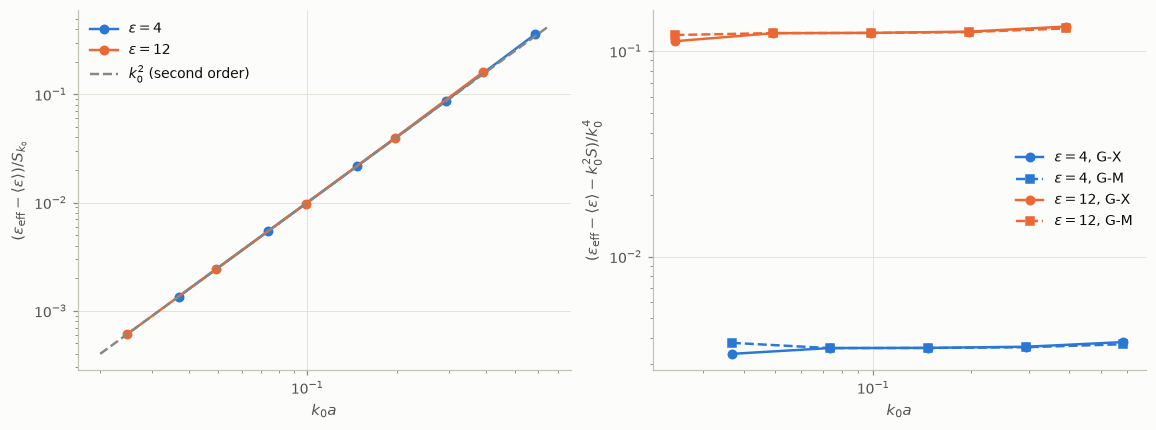

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10.4, 3.8))
for i, eps_r in enumerate((4.0, 12.0)):
    k0s = np.array([EFF[(eps_r, "G-X", Ka)][1] for Ka in Kas])
    effs = np.array([EFF[(eps_r, "G-X", Ka)][0] for Ka in Kas])
    ax[0].plot(k0s, (effs - PW[eps_r]["avg"]) / PW[eps_r]["Sk"], "o-", color=CAT[i], label=rf"$\varepsilon={eps_r:.0f}$")
kk = np.array([0.02, 0.65]); ax[0].plot(kk, kk**2, color=MUTED, ls="--", label=r"$k_0^2$ (second order)")
ax[0].set_xlabel(r"$k_0 a$"); ax[0].set_ylabel(r"$(\varepsilon_{\rm eff}-\langle\varepsilon\rangle)/S_{k_0}$"); ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].legend()
for i, eps_r in enumerate((4.0, 12.0)):
    for j, nm in enumerate(("G-X", "G-M")):
        ax[1].plot([EFF[(eps_r, nm, Ka)][1] for Ka in Kas], [EFF[(eps_r, nm, Ka)][2] for Ka in Kas], "o-" if j == 0 else "s--", color=CAT[i], label=rf"$\varepsilon={eps_r:.0f}$, {nm}")
ax[1].set_xlabel(r"$k_0 a$"); ax[1].set_ylabel(r"$(\varepsilon_{\rm eff}-\langle\varepsilon\rangle-k_0^2S)/k_0^4$"); ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].legend()
for a_ in ax: a_.xaxis.set_minor_formatter(NullFormatter())
plt.show()

*Figure 1.* Left: $(\varepsilon_{\rm eff}-\langle\varepsilon\rangle)/S$ from the plane-wave solver along $\Gamma X$ against $k_0a$ (dashed: $k_0^2$); both contrasts collapse on the second-order law. Right: the residual after the second-order term divided by $k_0^4$, along $\Gamma X$ and $\Gamma M$ for both contrasts: it is flat, which is what $O(k_0^4)$ means, and the two directions differ only at the next order ($\cos4\phi$ at $k_0^6$, quantified in the cell after the table).

**Reading the outputs.** The 1D sum equals Rytov's closed form to $7\times10^{-16}$ for three laminates. In 2D the 600-wave sums are $1.28744$ and $17.30895$ in $(a/\lambda)^2$. The truncation study (circular cutoff $|G|\le2\pi m$, $m=5,\dots,160$) shows the error of the 2D sum falling as $G_{\max}^{-3}$ (the summand falls as $G^{-5}$ per plane wave and a shell at $G$ has $\propto G$ of them): successive increments over doublings of $G_{\max}$ shrink by $7.46,\ 7.69,\ 7.86,\ 7.90$ (8 for a pure $G_{\max}^{-3}$ tail), and the extrapolated limits are $1.28755$ ($\varepsilon=4$) and $17.31042$ ($\varepsilon=12$), so the 600-wave sums are short by a relative $8.5\times10^{-5}$ (the column $|G|<40\pi$ is the $m=20$ row, still $3\times10^{-5}$ short for $\varepsilon=4$). The first shell of four reciprocal vectors gives $1.09548$ (equal to the closed form with $J_1$ to $10^{-16}$), which is $0.851$ of the sum, so a hand estimate from the first shell is off by 15%, not 5%. The $\varepsilon=12$ to $\varepsilon=4$ ratio of the sums is $(11/3)^2$ by construction (the sum is quadratic in the contrast), so it is not a test and is not asserted. The band computation gives $(\varepsilon_{\rm eff}-\langle\varepsilon\rangle)/(k_0^2S)=1.00014$ and $1.00016$ at $Ka=0.05$ and the table shows the coefficient drifting upward as $1+O(k_0^2)$ ($1.0096$ at $Ka=0.4$ for $\varepsilon=4$); along $\Gamma X$ and $\Gamma M$ the $k_0^2$ coefficient agrees to $1.8\times10^{-5}$ ($\varepsilon=4$) and $1.1\times10^{-5}$ ($\varepsilon=12$). The $k_0^4$ coefficient is about $0.0036$ ($\varepsilon=4$) and $0.12$ ($\varepsilon=12$), constant between $Ka=0.1$ and $0.2$ to $0.2\%$ and $0.4\%$; along the two directions it agrees to $0.15\%$ and $0.12\%$ at $Ka=0.2$ (the values at $Ka=0.05$ carry the roundoff of the eigenvalue: $k_0^4\approx2\times10^{-6}$ there, so an eigenvalue error of $10^{-9}$ in $\varepsilon_{\rm eff}$ shows as $\sim5\times10^{-4}$). This agreement is the $C_4$ prediction, not an observed anisotropy. What does differ is the $\cos4\phi$ term: the difference of the $k_0^4$ coefficient between $\Gamma X$ and $\Gamma M$ is $5.2\times10^{-6}$, $2.1\times10^{-5}$, $9.1\times10^{-5}$ at $Ka=0.2,\,0.4,\,0.8$ ($\varepsilon=4$) and grows by $4.38$ ($\varepsilon=4$) and $4.43$ ($\varepsilon=12$) from $Ka=0.4$ to $0.8$ (4 for a $k_0^2$ growth of a coefficient that multiplies $k_0^4$, i.e. $\cos4\phi$ at $O(k_0^6)$), and the $22.5^\circ$ direction, where $\cos4\phi=0$, equals the mean of the two to $5\times10^{-6}$ and $1\times10^{-5}$ of their difference at $Ka=0.4$.

## 2. The Born cutoff

At first order in the contrast the scattered field is $d(\mathbf r_t,\mathbf r_r)=\int G(\mathbf r_r,\mathbf r')\chi(\mathbf r')u_{\rm inc}(\mathbf r',\mathbf r_t)\,d\mathbf r'$. When the object is small against the antenna radii both factors are plane waves across it, $u_{\rm inc}\sim e^{i\mathbf k_t\cdot\mathbf r'}$ and $G\sim e^{-i\mathbf k_r\cdot\mathbf r'}$ (with $\mathbf k_t$ and $\mathbf k_r$ of length $k_0$), so $d\propto\hat\chi(\mathbf k_r-\mathbf k_t)$: the data sample the spatial spectrum of the object inside the disk $|\mathbf q|\le2k_0$ (the Ewald disk; $2$ cycles per wavelength). A lattice of period $p<\lambda_0/2$ has its first nonzero Fourier component at $1/p>2$ cycles per wavelength, outside the disk: at first order its bulk is invisible, and a *finite* patch of it shows only through the spectral content that the patch's shape and edge put inside the disk.

The experiment: $\chi=0.05\,w(\mathbf r)\cos(2\pi\kappa_gx)$ with the Gaussian window $w=e^{-r^2/2\cdot0.5^2}$, whose spectrum is Gaussian with sd $1/(2\pi\sigma_w)=0.32$ cycles per wavelength, so the window itself leaks past 2 cycles per wavelength, in amplitude as $\exp[-2\pi^2\sigma_w^2(\kappa_g-2)^2]$ (evaluated numerically below). The gain is $\|d_{\rm Born}\|/\|\chi\|_{L^2}$ for $\kappa_g=0.25\ldots4$ on two domains, the side $2.5$ first planned (PLAN.md), which cuts the window at $2.5\sigma_w$, where it still has $4\%$ of its peak) and side $3.5$, at $n=64$. The *prediction* uses no forward solve: it evaluates the sampled $\chi$'s transform at $(\mathbf k_r-\mathbf k_t)/2\pi$ for the 2400 (transmitter, receiver) pairs, takes the rms and divides by $\|\chi\|$, scaled to match the measured gain at $\kappa_g=1$ (one number). A hard-edged disk of radius 1 carrying the same grating is added to see what a sharp boundary does.

In [8]:
# gains on two domains, with the leakage predicted from the sampled chi itself
kap = np.array([0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 2.75, 3.0, 3.5, 4.0])
GAIN, PRED = {}, {}
th_t = np.arctan2(tx[:, 1], tx[:, 0]); th_r = np.arctan2(rx[:, 1], rx[:, 0])
nu = (np.stack([np.cos(th_r)[None, :] - np.cos(th_t)[:, None], np.sin(th_r)[None, :] - np.sin(th_t)[:, None]], -1)).reshape(-1, 2)   # (k_r - k_t)/k0 per pair, in cycles per wavelength
t_born = time.perf_counter()
for side in (3.5, 2.5):
    st_ = ch15_setup(n=64, side=side)
    fw_ = Forward(st_, tol=1e-10)
    GAIN[side] = sc.born_grating_gain(fw_, kap)
    X_, Y_ = st_.grid.centers()
    w_ = np.exp(-(X_**2 + Y_**2) / (2 * 0.5**2))
    pr = []
    for kg in kap:
        chi_ = 0.05 * w_ * np.cos(2 * np.pi * kg * X_)
        ph_ = np.exp(-2j * np.pi * (nu[:, 0:1] * X_.ravel()[None, :] + nu[:, 1:2] * Y_.ravel()[None, :]))
        ch_hat = ph_ @ chi_.ravel() * st_.grid.h**2                   # chi_hat(nu) at the sampled (t, r) pairs
        pr.append(np.sqrt(np.mean(np.abs(ch_hat) ** 2)) / (st_.grid.h * np.linalg.norm(chi_)))
    PRED[side] = np.array(pr)
print(f"Born gains and the spectral prediction took {time.perf_counter() - t_born:.1f} s")
i1 = list(kap).index(1.0)
rows = [(k, GAIN[3.5][i], GAIN[2.5][i], PRED[3.5][i] / PRED[3.5][i1] * GAIN[3.5][i1], PRED[2.5][i] / PRED[2.5][i1] * GAIN[2.5][i1]) for i, k in enumerate(kap)]
table(["kappa_g", "gain side 3.5", "gain side 2.5", "predicted 3.5", "predicted 2.5"], rows, [".2f", ".5f", ".5f", ".5f", ".5f"])
ik = {k: i for i, k in enumerate(kap)}
r35 = GAIN[3.5][ik[3.0]] / GAIN[3.5][ik[1.5]]
r25 = GAIN[2.5][ik[3.0]] / GAIN[2.5][ik[1.5]]
r25b = GAIN[2.5][ik[4.0]] / GAIN[2.5][ik[1.5]]
print(f"gain(3)/gain(1.5): side 3.5 {r35:.4f}, side 2.5 {r25:.4f};  gain(4)/gain(1.5) on side 2.5: {r25b:.4f}")
check_in("Born knee: gain(3)/gain(1.5) on the side-3.5 domain", r35, 0.0, 1e-2)
check_in("Born knee on the side-2.5 domain of PLAN.md: gain(3)/gain(1.5) exceeds 1e-2 (truncated window leaks)", r25, 1e-2, 3e-2)
check_in("Born knee on side 2.5: gain(4)/gain(1.5) <= 1e-2 (alternative statement of the knee)", r25b, 0.0, 1e-2)
pr_ratio = np.array([[GAIN[sd][i] / (PRED[sd][i] / PRED[sd][i1] * GAIN[sd][i1]) for i in range(len(kap))] for sd in (3.5, 2.5)])
print(f"measured/predicted gain over kappa_g in [0.25, 4]: side 3.5 in [{pr_ratio[0].min():.3f}, {pr_ratio[0].max():.3f}], side 2.5 in [{pr_ratio[1].min():.3f}, {pr_ratio[1].max():.3f}]")
check_in("measured gain over the plane-wave spectral prediction, all kappa_g (side 3.5): spread", pr_ratio[0].max() / pr_ratio[0].min(), 1.0, 1.15)
check_in("measured gain over the spectral prediction, all kappa_g (side 2.5): spread", pr_ratio[1].max() / pr_ratio[1].min(), 1.0, 1.15)
# converged in n, and a hard-edged patch
gb = sc.born_grating_gain(Forward(ch15_setup(n=48, side=3.5), tol=1e-10), kap)
conv = np.abs(gb / GAIN[3.5] - 1)
print("n = 48 vs 64 (side 3.5), relative difference of the gain by kappa_g: " + ", ".join(f"{k:g}: {c:.1e}" for k, c in zip(kap, conv)))
check("Born gain converged in n: n = 48 vs 64, side 3.5, max rel over kappa_g <= 2.5 (the gain is >= 0.12 there)", float(conv[kap <= 2.5].max()), 1e-2)
st35 = ch15_setup(n=64, side=3.5); fw35 = Forward(st35, tol=1e-10)
X35, Y35 = st35.grid.centers()
hard = []
for kg in (1.0, 1.5, 3.0):
    chi_ = 0.05 * (X35**2 + Y35**2 < 1.0) * np.cos(2 * np.pi * kg * X35)
    hard.append(np.linalg.norm(np.asarray(fw35.born(chi_))) / (st35.grid.h * np.linalg.norm(chi_)))
print(f"hard-edged patch (disk of radius 1): gain at kappa_g = 1, 1.5, 3: {hard[0]:.4f}, {hard[1]:.4f}, {hard[2]:.4f}; gain(3)/gain(1.5) = {hard[2] / hard[1]:.4f}")
check_in("a sharp boundary shows what the bulk grating does not: hard-edged gain(3)/gain(1.5) exceeds the windowed 3.5e-3 by 10x", hard[2] / hard[1] / r35, 10.0, 1e4)
# the hard-edged disk has a pixel-staircase boundary, so repeat it at n = 128 (h halved); the windowed ratio is converged in n
st128 = ch15_setup(n=128, side=3.5); fw128 = Forward(st128, tol=1e-10)
X128, Y128 = st128.grid.centers()
hard128 = []
for kg in (1.0, 1.5, 3.0):
    chi_ = 0.05 * (X128**2 + Y128**2 < 1.0) * np.cos(2 * np.pi * kg * X128)
    hard128.append(np.linalg.norm(np.asarray(fw128.born(chi_))) / (st128.grid.h * np.linalg.norm(chi_)))
print(f"hard-edged disk at n = 128: gain at kappa_g = 1, 1.5, 3: {hard128[0]:.4f}, {hard128[1]:.4f}, {hard128[2]:.4f}; gain(3)/gain(1.5) = {hard128[2] / hard128[1]:.4f}; "
      f"over the windowed ratio {r35:.4f}: {hard[2] / hard[1] / r35:.0f} (n = 64), {hard128[2] / hard128[1] / r35:.0f} (n = 128)")
check_in("hard-edged disk, n = 128: gain(3)/gain(1.5) still exceeds the windowed ratio by 10x (the staircase is not what transmits it)", hard128[2] / hard128[1] / r35, 10.0, 1e4)
check_in("hard-edged gain(3)/gain(1.5), n = 64 vs 128: the two agree within 10% (the factor is quoted as about 40)", abs(hard[2] / hard[1] / (hard128[2] / hard128[1]) - 1), 0.0, 0.10)

Born gains and the spectral prediction took 4.2 s
kappa_g  gain side 3.5  gain side 2.5  predicted 3.5  predicted 2.5
   0.25        1.40770        1.40915        1.40893        1.41043
   0.50        1.05014        1.05157        1.05162        1.05308
   0.75        0.80660        0.80757        0.80679        0.80775
   1.00        0.71066        0.71241        0.71066        0.71241
   1.25        0.67152        0.67285        0.67155        0.67291
   1.50        0.68174        0.68481        0.68183        0.68492
   1.75        0.71948        0.71996        0.71950        0.72001
   2.00        0.63204        0.62979        0.63176        0.62955
   2.25        0.36550        0.37264        0.36507        0.37221
   2.50        0.12385        0.12287        0.12361        0.12261
   2.75        0.02395        0.02077        0.02388        0.02067
   3.00        0.00236        0.01222        0.00235        0.01203
   3.50        0.00024        0.00816        0.00023        0.0080

hard-edged patch (disk of radius 1): gain at kappa_g = 1, 1.5, 3: 0.6954, 0.6533, 0.0965; gain(3)/gain(1.5) = 0.1477
PASS  a sharp boundary shows what the bulk grating does not: hard-edged gain(3)/gain(1.5) exceeds the windowed 3.5e-3 by 10x: got 42.632, required in [10, 10000]


hard-edged disk at n = 128: gain at kappa_g = 1, 1.5, 3: 0.6964, 0.6552, 0.0897; gain(3)/gain(1.5) = 0.1370; over the windowed ratio 0.0035: 43 (n = 64), 40 (n = 128)
PASS  hard-edged disk, n = 128: gain(3)/gain(1.5) still exceeds the windowed ratio by 10x (the staircase is not what transmits it): got 39.5198, required in [10, 10000]
PASS  hard-edged gain(3)/gain(1.5), n = 64 vs 128: the two agree within 10% (the factor is quoted as about 40): got 0.0787492, required in [0, 0.1]


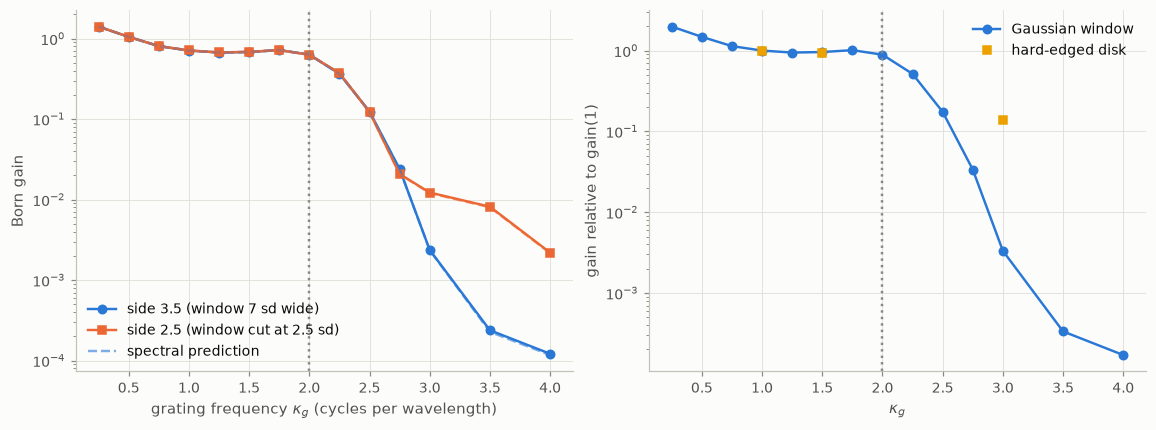

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10.4, 3.8))
ax[0].semilogy(kap, GAIN[3.5], "o-", color=CAT[0], label="side 3.5 (window 7 sd wide)")
ax[0].semilogy(kap, GAIN[2.5], "s-", color=CAT[1], label="side 2.5 (window cut at 2.5 sd)")
ax[0].semilogy(kap, PRED[3.5] / PRED[3.5][i1] * GAIN[3.5][i1], "--", color=CAT[0], alpha=0.6, label="spectral prediction")
ax[0].semilogy(kap, PRED[2.5] / PRED[2.5][i1] * GAIN[2.5][i1], "--", color=CAT[1], alpha=0.6)
ax[0].axvline(2.0, color=MUTED, ls=":")
ax[0].set_xlabel(r"grating frequency $\kappa_g$ (cycles per wavelength)"); ax[0].set_ylabel("Born gain"); ax[0].legend()
ax[1].semilogy(kap, np.array([GAIN[3.5][i] for i in range(len(kap))]) / GAIN[3.5][i1], "o-", color=CAT[0], label="Gaussian window")
ax[1].semilogy([1.0, 1.5, 3.0], np.array(hard) / hard[0], "s", color=CAT[3], label="hard-edged disk")
ax[1].axvline(2.0, color=MUTED, ls=":"); ax[1].set_xlabel(r"$\kappa_g$"); ax[1].set_ylabel("gain relative to gain(1)"); ax[1].legend()
plt.show()

*Figure 2.* Left: Born gain against grating frequency on the two domains with the spectral prediction (dashed, one scale factor fitted at $\kappa_g=1$); the vertical line is the Ewald edge at 2 cycles per wavelength. Right: the gain relative to $\kappa_g=1$ for the windowed grating and for a hard-edged disk carrying the grating.

**Reading the outputs.** Both domains give the same gains up to $\kappa_g=2.5$ ($0.71$ at 1, $0.68$ at 1.5, $0.63$ at 2, $0.124$ at 2.5), the knee at 2 cycles per wavelength. Beyond it the side-3.5 gain falls to $0.0024$ at $\kappa_g=3$ (ratio to $\kappa_g=1.5$: $0.0035$, passing the bound $10^{-2}$), whereas the side-2.5 gain levels off at $0.0122$, $0.0082$, $0.0022$ at $\kappa_g=3,\ 3.5,\ 4$: the ratio at 3 is $0.0179$, which fails the bound $10^{-2}$ expected in PLAN.md, while the alternative statement $\text{gain}(4)/\text{gain}(1.5)=0.0032$ passes. The expectation $\le10^{-2}$ on side 2.5 was wrong because the hard truncation of the window at 2.5 sd puts spectral content outside the Ewald disk, not because of the discretization (the gain is converged in $n$: $n=48$ against $64$ differ by at most $4.7\times10^{-3}$ up to $\kappa_g=3$, and by $7\times10^{-2}$ and $0.10$ at 3.5 and 4, where the gain is $10^{-4}$ and pixel-scale content matters). The spectral prediction agrees with the measured gain to within a spread of $4.9\%$ on side 3.5 and $2.0\%$ on side 2.5, for gains that range over four decades, so the knee, its softness and the leakage are all the Ewald disk applied to the window's spectrum, to the accuracy of the plane-wave approximation. The hard-edged disk has gain ratio $0.148$ at $\kappa_g=3$ against $1.5$ at $n=64$ and $0.137$ at $n=128$ (its pixel-staircase boundary changes the ratio by $8\%$ on halving the cell), $43$ and $40$ times the windowed value, so about 40 times: the sub-wavelength grating is not seen in the bulk at first order, but the boundary of a finite patch transmits it. This is the statement the later sections need: below $\lambda_0/2$, what a scattering experiment sees of a microstructure at leading order is its average and its boundary.

## 3. Concentric rings: what a homogeneous fit absorbs

The truth is a disk of radius $R_D=1$ made of concentric rings of period $p$, thickness fraction $f=\tfrac12$ of $\varepsilon_1=3$ followed by $\varepsilon_2=1.5$; $\bar\varepsilon=2.25$, $\bar\chi=1.25$, $\Delta\chi=\Delta\varepsilon=1.5$. Two terminations: the *period cut* (core $\varepsilon_1$, outermost $\varepsilon_2$ layer ending at $R_D$: $n_p=1/p$ whole periods) and the *mid-layer cut* (core and outermost layers of $\varepsilon_2$, the outermost of half thickness). Exact data come from the multilayer Mie series of `scatter.exact_data` (validated below against the testbed's Mie code, an independent J/Y interface-matching recursion, and, in section 4, the testbed forward solver). The model is a homogeneous disk $(\varepsilon,R)$, fitted by Gauss-Newton with analytic tangents on whitened data.

*Termination as a radius shift at $O(p)$.* Write $\chi=\bar\chi+\tilde\chi$ with $\tilde\chi$ oscillating at period $p$, let $X_0$ be its zero-mean antiderivative ($O(p)$) and $X_1$ the zero-mean antiderivative of $X_0$ ($O(p^2)$). For a centered radial object the Born data are $\propto\int_0^{R_D}\chi(r)\,g_n(r)\,dr$ with $g_n=rJ_n(k_0r)^2$, $g_n(0)=0$ and $g_n'(0)=\delta_{n0}$. Integrating the oscillating part by parts twice gives

$$\int_0^{R_D}\tilde\chi\,g_n\,dr=\big[X_0g_n-X_1g_n'\big]_0^{R_D}+\int_0^{R_D}X_1g_n''\,dr,$$

and the last integral is $O(p^3)$ because $X_1$ has zero mean and oscillates. So at Born order *everything* that survives the integration is a boundary term: no power of $p$ comes from the bulk (the bulk enters first at second order in the contrast, as the Rytov term, outside this integral). The term $X_0(R_D)g_n(R_D)$ has the form of a change $\delta R=X_0(R_D)/\bar\chi$ of the radius of the homogeneous disk, which is the only $O(p)$ effect. The remainder is a boundary term $O(p^2)$ at $R_D$ ($-X_1(R_D)g_n'(R_D)$) and, for $n=0$, at the center ($-X_1(0)$, since $g_0'(0)=1$): it is linear in the contrast and depends on where the structure starts and ends, not only on the outer cut. For the two cuts $X_0(R_D)=-\Delta\chi f(1-f)p/2$ and $0$, so $\delta R_{\rm pred}=-0.15\,p$ for the period cut and $\delta R=0$ at $O(p)$ for the mid cut. The data error $\delta$ with respect to the $(\bar\varepsilon,R_D)$ disk is therefore $O(p)$ for the period cut and $O(p^2)$ for the mid cut; once the radius shift is absorbed what remains in the normal space is $O(p^2)$, so $z_\varepsilon\propto p^2$, $\Delta\Phi\propto p^4$ and $c=\Delta\Phi/z^2$ is constant. This notebook shows the $O(p)$ radius shift with its measured deficit (about $1.1p$ relative); it does not show that the shift is exact beyond Born, and no claim below depends on that. For the period cut the shift is large against the posterior sd ($\sigma_R=7.4\times10^{-5}$), so the base-point linearization of DESIGN 15.1 is not trusted: the analysis is done at the *profile foot point* (eps fixed at $\bar\varepsilon$, $R$ at its least-squares value), and both frames are printed.

The table lists, for $n_p=5\ldots80$ ($p=0.2\ldots0.0125$) and each cut: the raw relative error against the $(\bar\varepsilon,R_D)$ disk, the radius shift of the $R$-only fit, the permittivity shift of the $(\varepsilon,R)$ fit and its ratio to Rytov's term, the first-order $z$ and $\Delta\Phi$ (foot point for the period cut, base point for the mid cut), the same from the noise-free nonlinear fit, and the angle $\alpha$ and $c$.

In [10]:
e1, e2, f, RD = 3.0, 1.5, 0.5, 1.0
ebar, chibar, dchi = f * e1 + (1 - f) * e2, f * e1 + (1 - f) * e2 - 1, e1 - e2
d0 = sc.exact_data(tx, rx, [RD], [ebar])
s0 = sc.noise_level(d0, 30.0)
D0 = sc.disk_jacobian([ebar, RD], tx, rx, s0)
sig0 = np.sqrt(np.diag(np.linalg.inv(D0.T @ D0)))
print(f"epsbar = {ebar}, chibar = {chibar}, noise s = {s0:.3e} (30 dB), posterior sd at the base: eps {sig0[0]:.3e}, R {sig0[1]:.3e}")
# multilayer code against the testbed Mie series
from bayes_scatter.mie import mie_scattered
ref = mie_scattered(tx, rx, 1.0, ebar)
check("multilayer exact_data vs bayes_scatter.mie.mie_scattered, homogeneous disk (max rel)", float(np.abs(d0 - ref).max() / np.abs(ref).max()), 1e-12)
rr, ee = sc.rings(RD, 20, f, e1, e2, "period")


def multilayer_jy(radii, eps, k0=2 * np.pi, M=26):
    """Independent multilayer coefficients: u = A J_m(k r) + B Y_m(k r) in each layer, u and du/dr matched at every interface (2 x 2 solves),
    s_m = -iB/(A + iB) in the vacuum outside (u = a [J_m + s_m H_m^(1)]). Used only to test sc.multilayer."""
    s_ = np.zeros(M + 1, complex)
    ks = k0 * np.sqrt(np.asarray(eps, complex))
    for m in range(M + 1):
        AB = np.array([1.0, 0.0], complex)                                  # regular in the core
        for j in range(len(radii)):
            r, kj = radii[j], ks[j]
            kn = ks[j + 1] if j + 1 < len(radii) else k0
            Mj = np.array([[special.jv(m, kj * r), special.yv(m, kj * r)], [kj * special.jvp(m, kj * r), kj * special.yvp(m, kj * r)]])
            Mn = np.array([[special.jv(m, kn * r), special.yv(m, kn * r)], [kn * special.jvp(m, kn * r), kn * special.yvp(m, kn * r)]])
            AB = np.linalg.solve(Mn, Mj @ AB)
        s_[m] = -1j * AB[1] / (AB[0] + 1j * AB[1])
    return s_


for n_chk in (5, 20):
    rr_c, ee_c = sc.rings(RD, n_chk, f, e1, e2, "period")
    s_a, s_b = sc.multilayer(rr_c, ee_c, M=26), multilayer_jy(rr_c, ee_c)
    check(f"multilayer series (sc.multilayer) vs an independent J/Y interface-matching recursion, period cut n_p = {n_chk}, orders 0-26 (max |diff|/max |s|)", float(np.abs(s_a - s_b).max() / np.abs(s_b).max()), 1e-9)
check("M = 60 vs 90 orders, ring structure n_p = 20 (rel)", rel(sc.exact_data(tx, rx, rr, ee, M=60), sc.exact_data(tx, rx, rr, ee, M=90)), 1e-12)


def ring_case(cut, n_p, a1=e1, a2=e2, truth=None):
    """Exact data of a ring structure and the fits and first-order analyses against the (epsbar, R_D) disk."""
    fr = f
    eb = fr * a1 + (1 - fr) * a2
    p = RD / n_p
    d = sc.exact_data(tx, rx, *sc.rings(RD, n_p, fr, a1, a2, cut)) if truth is None else sc.mie_disk(truth, RD, (0, 0), tx, rx)
    dbase = sc.mie_disk(eb, RD, (0, 0), tx, rx)
    Db = sc.disk_jacobian([eb, RD], tx, rx, s0)
    pR, DR, rR = sc.fit_disk(d, tx, rx, [eb, RD], s0, free=("R",))
    p2, D2, r2 = sc.fit_disk(d, tx, rx, [eb, RD], s0)
    base = det.analyze_error(Db, sc.whitened_delta(d, dbase, s0))
    pf, Df, rf = sc.foot_point_R(d, tx, rx, eb, RD, s0)
    foot = det.analyze_error(Df, rf)
    first = foot if cut == "period" else base
    zNL = (p2[0] - eb) / first["sigma"][0]
    ryt = sc.rytov_tm(fr, a1, a2, p)
    return dict(p=p, raw=rel(d, dbase), dRfit=pR[1] - RD, dRpred=-(a1 - a2) * fr * (1 - fr) * p / 2 / (eb - 1), deps=p2[0] - eb, rytov=ryt,
                dphiNL=0.5 * float(r2 @ r2), base=base, foot=foot, first=first, zNL=zNL, d=d)


NPS = [5, 10, 20, 40, 80]
t_rings = time.perf_counter()
ROW = {cut: {n: ring_case(cut, n) for n in NPS} for cut in ("period", "mid")}
print(f"ring table computed in {time.perf_counter() - t_rings:.1f} s")
for cut in ("period", "mid"):
    print(f"\ncut = {cut}  (first-order analysis at the {'foot point' if cut == 'period' else 'base point'})")
    col = "dR_fit/dR_pred" if cut == "period" else "dR_fit/p"
    table(["n_p", "p", "raw rel err", "dR_fit", col, "d_eps fit", "d_eps/Rytov", "z first", "z NL", "dPhi first", "dPhi NL", "alpha deg", "c"],
          [(n, r["p"], r["raw"], r["dRfit"], r["dRfit"] / r["dRpred"] if cut == "period" else r["dRfit"] / r["p"], r["deps"], r["deps"] / r["rytov"], r["first"]["z"], r["zNL"],
            r["first"]["dphi"], r["dphiNL"], np.degrees(r["first"]["alpha"]), r["first"]["c_direct"]) for n, r in ROW[cut].items()],
          ["d", ".4f", ".3e", ".3e", ".3f" if cut == "period" else ".4f", ".3e", ".3f", ".3f", ".3f", ".4g", ".4g", ".2f", ".3f"])

epsbar = 2.25, chibar = 1.25, noise s = 4.358e-04 (30 dB), posterior sd at the base: eps 2.656e-04, R 7.440e-05
PASS  multilayer exact_data vs bayes_scatter.mie.mie_scattered, homogeneous disk (max rel): got 2.1809e-15, target 0, |diff| 2.18e-15 <= 1e-12
PASS  multilayer series (sc.multilayer) vs an independent J/Y interface-matching recursion, period cut n_p = 5, orders 0-26 (max |diff|/max |s|): got 6.04237e-14, target 0, |diff| 6.04e-14 <= 1e-09
PASS  multilayer series (sc.multilayer) vs an independent J/Y interface-matching recursion, period cut n_p = 20, orders 0-26 (max |diff|/max |s|): got 3.44074e-14, target 0, |diff| 3.44e-14 <= 1e-09
PASS  M = 60 vs 90 orders, ring structure n_p = 20 (rel): got 0, target 0, |diff| 0.00e+00 <= 1e-12


ring table computed in 2.0 s

cut = period  (first-order analysis at the foot point)
n_p       p  raw rel err      dR_fit  dR_fit/dR_pred  d_eps fit  d_eps/Rytov  z first     z NL  dPhi first  dPhi NL  alpha deg      c
  5  0.2000    4.515e-01  -2.580e-02           0.860  2.686e-02        1.451  107.702  108.567        5322     5315      43.77  0.459
 10  0.1000    2.421e-01  -1.366e-02           0.911  4.301e-03        0.930   17.014   17.021       149.6    149.7      45.47  0.517
 20  0.0500    1.221e-01  -7.123e-03           0.950  9.369e-04        0.810    3.633    3.633       7.711    7.712      47.23  0.584
 40  0.0250    6.086e-02  -3.650e-03           0.973  2.224e-04        0.769    0.851    0.851      0.4543   0.4543      48.25  0.627
 80  0.0125    3.032e-02  -1.849e-03           0.986  5.442e-05        0.753    0.207    0.207     0.02782  0.02782      48.78  0.652

cut = mid  (first-order analysis at the base point)
n_p       p  raw rel err     dR_fit  dR_fit/p  d_eps fit  

In [11]:
# checks of the section: slopes, termination, law identity, first order vs nonlinear fit
pv = np.array([RD / n for n in NPS])
s_per = np.polyfit(np.log(pv[1:]), np.log([ROW["period"][n]["raw"] for n in NPS[1:]]), 1)[0]
s_mid = np.polyfit(np.log(pv[1:]), np.log([ROW["mid"][n]["raw"] for n in NPS[1:]]), 1)[0]
print(f"raw-error slopes in p over n_p = 10-80: period {s_per:.3f}, mid {s_mid:.3f}")
check("raw error slope, period cut: 1 +- 0.1", s_per, 0.1, 1.0)
check("raw error slope, mid cut: 2 +- 0.15", s_mid, 0.15, 2.0)
rat = np.array([ROW["period"][n]["dRfit"] / ROW["period"][n]["dRpred"] for n in NPS])
check("termination = radius shift, period cut, p = 0.025: |dR_fit/dR_pred - 1|", abs(rat[3] - 1), 0.05)
check("termination = radius shift, period cut, p = 0.0125: |dR_fit/dR_pred - 1|", abs(rat[4] - 1), 0.05)
print("deficit 1 - dR_fit/dR_pred by n_p: " + ", ".join(f"{1 - r:.4f}" for r in rat) + f";  deficit/p: " + ", ".join(f"{(1 - r) / p:.2f}" for r, p in zip(rat, pv)))
# deficit = a p + b p^2 fitted on n_p = 10 ... 80 (is the O(p) coefficient finite, and what is it?)
defi = 1 - rat
Amat = np.stack([pv[1:], pv[1:] ** 2], axis=1)
(a_def, b_def), *_ = np.linalg.lstsq(Amat, defi[1:], rcond=None)
res_def = float(np.max(np.abs(Amat @ np.array([a_def, b_def]) - defi[1:]) / defi[1:]))
print(f"deficit = a p + b p^2 on n_p = 10-80: a = {a_def:.3f}, b = {b_def:.2f}; max relative residual of the fit {res_def:.1e}")
check_in("deficit of the radius shift is a p + b p^2 with a near 1.1 (fit n_p = 10-80; observed a = 1.13): a", float(a_def), 0.9, 1.4)
check_in("... and the two-term fit describes the deficit at n_p = 10, 20, 40, 80: max relative residual", res_def, 0.0, 0.05)
check_in("mid cut: radius shift is O(p^2): dR_fit(p = 0.0125)/dR_fit(p = 0.025) near 1/4", ROW["mid"][80]["dRfit"] / ROW["mid"][40]["dRfit"], 0.2, 0.3)
cg = max(abs(r["base"]["c_geom"] - r["base"]["c_direct"]) / r["base"]["c_direct"] for c_ in ROW for r in ROW[c_].values())
cgf = max(abs(r["foot"]["c_geom"] - r["foot"]["c_direct"]) / r["foot"]["c_direct"] for c_ in ROW for r in ROW[c_].values())
check("law identity c_geom = c_direct, base point, all cases (max rel)", cg, 1e-10)
check("law identity c_geom = c_direct, foot point, all cases (max rel)", cgf, 1e-10)
small = [n for n in NPS if RD / n <= 0.05 + 1e-12]
zr = max(abs(ROW[c_][n]["first"]["z"] / ROW[c_][n]["zNL"] - 1) for c_ in ROW for n in small)
dr_ = max(abs(ROW[c_][n]["first"]["dphi"] / ROW[c_][n]["dphiNL"] - 1) for c_ in ROW for n in small)
print(f"first order vs nonlinear fit, p <= 0.05: max rel difference of z {zr:.4f}, of DeltaPhi {dr_:.4f}")
check("first order (period: foot point, mid: base point) vs noise-free nonlinear fit, p <= 0.05: z, max rel", zr, 5e-2)
check("first order vs noise-free nonlinear fit, p <= 0.05: DeltaPhi, max rel", dr_, 1e-1)
for c_ in ROW:
    print(f"  {c_}: z first/NL at p = 0.05: {ROW[c_][20]['first']['z']:.3f}/{ROW[c_][20]['zNL']:.3f}, DeltaPhi {ROW[c_][20]['first']['dphi']:.3f}/{ROW[c_][20]['dphiNL']:.3f}")
base_per = ROW["period"][40]["base"]["dphi"] / ROW["period"][40]["dphiNL"]
base_per10 = ROW["period"][10]["base"]["dphi"] / ROW["period"][10]["dphiNL"]
print(f"period cut linearized at the BASE point: DeltaPhi_1st/DeltaPhi_NL = {base_per10:.0f} at p = 0.1, {base_per:.0f} at p = 0.025; z_base = {ROW['period'][40]['base']['z']:.1f} vs foot z = {ROW['period'][40]['foot']['z']:.3f}")
check_in("linearizing the period cut at the base point overshoots DeltaPhi (p = 0.025): ratio", base_per, 30.0, 300.0)

raw-error slopes in p over n_p = 10-80: period 1.000, mid 2.013
PASS  raw error slope, period cut: 1 +- 0.1: got 0.999665, target 1, |diff| 3.35e-04 <= 1e-01
PASS  raw error slope, mid cut: 2 +- 0.15: got 2.01336, target 2, |diff| 1.34e-02 <= 1e-01
PASS  termination = radius shift, period cut, p = 0.025: |dR_fit/dR_pred - 1|: got 0.0266717, target 0, |diff| 2.67e-02 <= 5e-02
PASS  termination = radius shift, period cut, p = 0.0125: |dR_fit/dR_pred - 1|: got 0.0137454, target 0, |diff| 1.37e-02 <= 5e-02
deficit 1 - dR_fit/dR_pred by n_p: 0.1398, 0.0895, 0.0503, 0.0267, 0.0137;  deficit/p: 0.70, 0.89, 1.01, 1.07, 1.10
deficit = a p + b p^2 on n_p = 10-80: a = 1.120, b = -2.25; max relative residual of the fit 7.1e-03
PASS  deficit of the radius shift is a p + b p^2 with a near 1.1 (fit n_p = 10-80; observed a = 1.13): a: got 1.11999, required in [0.9, 1.4]
PASS  ... and the two-term fit describes the deficit at n_p = 10, 20, 40, 80: max relative residual: got 0.00708445, required in [0, 

In [12]:
# scaling and the three windows (case mid, base point): log-log laws fitted on n_p = 20, 40, 80
zs = np.array([abs(ROW["mid"][n]["base"]["z"]) for n in NPS]); dps = np.array([ROW["mid"][n]["base"]["dphi"] for n in NPS])
sz = np.polyfit(np.log(pv), np.log(zs), 1)[0]; sd_ = np.polyfit(np.log(pv), np.log(dps), 1)[0]
print(f"slopes over n_p = 5-80 (mid): z {sz:.3f}, DeltaPhi {sd_:.3f};  over n_p = 10-80: z {np.polyfit(np.log(pv[1:]), np.log(zs[1:]), 1)[0]:.3f}, DeltaPhi {np.polyfit(np.log(pv[1:]), np.log(dps[1:]), 1)[0]:.3f}")
sz2 = np.polyfit(np.log(pv[1:]), np.log(zs[1:]), 1)[0]; sd2 = np.polyfit(np.log(pv[1:]), np.log(dps[1:]), 1)[0]
check("slope of z_eps in p (mid, n_p = 10-80): 2 +- 0.15", sz2, 0.15, 2.0)
check("slope of DeltaPhi in p (mid, n_p = 10-80): 4 +- 0.3", sd2, 0.3, 4.0)
p_z, _ = sc.loglog_crossing(pv[2:], zs[2:], 3.0)
p_flag, _ = sc.loglog_crossing(pv[2:], dps[2:], FLAG)
p_3, _ = sc.loglog_crossing(pv[2:], dps[2:], 3.0)
cmid = np.array([ROW["mid"][n]["base"]["c_direct"] for n in NPS])
print(f"windows from log-log laws on n_p = 20-80 (mid): p_3nat = {p_3:.4f}, p_z = {p_z:.4f}, p_flag = {p_flag:.4f};  c = DeltaPhi/z^2 at n_p = 20, 40, 80: {cmid[2]:.3f}, {cmid[3]:.3f}, {cmid[4]:.3f}")
check_in("c = DeltaPhi/z^2 at p = 0.0125 lies in (3/9, flag/9)", cmid[4], 3 / 9, FLAG / 9)
check_in("ordering p_3nat < p_z < p_flag, case mid", float(p_3 < p_z < p_flag), 1.0, 1.0)
check("windows vs a preliminary calculation (0.032, 0.046, 0.084): max rel", max(abs(p_3 / 0.032 - 1), abs(p_z / 0.046 - 1), abs(p_flag / 0.084 - 1)), 0.05)
check_in("angle alpha of the normal residual at p = 0.0125, mid (degrees)", np.degrees(ROW["mid"][80]["base"]["alpha"]), 17.9, 18.1)
# direct evaluation at integer n_p near the window ends, at p = 0.07 (the structure of section 5, n_p = 14.29) and at three core phases near n_p = 15;
# for each structure also the swapped layer order, and the standardized error of the fitted eps against <eps> (= z) and against <eps> + Rytov
rows, rows2, DIR = [], [], {}
thr = 2 * (N_DATA + FLAG)
for n in (22, 15, 12, 1 / 0.07, 15.25, 15.5, 15.75):
    r = ring_case("mid", n)
    rs = ring_case("mid", n, a1=e2, a2=e1)
    a = r["base"]
    P_nc = float(stats.ncx2.sf(thr, 2 * N_DATA - 2, 2 * a["dphi"]))          # chi^2_{4800-2}(noncentrality 2 DeltaPhi): exact for the linear model
    P_pl = float(stats.chi2.sf(2 * (N_DATA + FLAG - a["dphi"]), 2 * N_DATA))  # the shifted form P(chi2_4800/2 + DeltaPhi > 2400 + 147)
    P_nl = float(stats.ncx2.sf(thr, 2 * N_DATA - 2, 2 * r["dphiNL"]))        # the same with the misfit of the noise-free nonlinear fit
    DIR[n] = dict(r=r, rs=rs, P_nc=P_nc, P_pl=P_pl, P_nl=P_nl, off=(r["deps"] - r["rytov"]) / a["sigma"][0], offs=(rs["deps"] - rs["rytov"]) / rs["base"]["sigma"][0])
    rows.append((n, r["p"], a["z"], r["zNL"], a["dphi"], r["dphiNL"], a["c_direct"], P_nc, P_nl, P_pl))
    rows2.append((n, r["p"], r["rytov"] / a["sigma"][0], r["deps"] / r["rytov"], DIR[n]["off"], rs["deps"] / rs["rytov"], DIR[n]["offs"]))
table(["n_p", "p", "z first", "z NL", "dPhi first", "dPhi NL", "c", "P(flag) ncx2", "P(flag) with dPhi NL", "P(flag) shifted"], rows, [".4f", ".4f", ".3f", ".3f", ".2f", ".2f", ".3f", ".4f", ".4f", ".4f"])
print("\nthe same structures against the two targets: <eps> (the error is d_eps, in sd: z) and <eps> + Rytov (the error is d_eps - Rytov);  mid cut, layer order as in the text and swapped")
table(["n_p", "p", "Rytov/sd", "d_eps/Ry orig", "(d_eps - Ry)/sd orig", "d_eps/Ry swap", "(d_eps - Ry)/sd swap"], rows2, [".4f", ".4f", ".3f", ".3f", ".2f", ".3f", ".2f"])
INT = (22, 15, 12)
off_o = np.array([DIR[n]["off"] for n in INT]); off_s = np.array([DIR[n]["offs"] for n in INT])
nonint = (1 / 0.07, 15.25, 15.5, 15.75)
check_in("integer-n_p mid-cut family, p = 1/22, 1/15, 1/12: max |d_eps - Rytov|/sd, layer order as in the text, is below 2.1 (reading (b); window set after seeing 1.99)", float(np.abs(off_o).max()), 0.0, 2.1)
check_in("integer-n_p family, swapped layer order: |d_eps - Rytov|/sd at p = 1/22 and 1/15 below 2.1 (set after seeing 0.85 and 2.03)", float(np.abs(off_s[:2]).max()), 0.0, 2.1)
check_in("integer-n_p family, swapped layer order: |d_eps - Rytov|/sd at p = 1/12 exceeds 3 (observed 3.53)", float(abs(off_s[2])), 3.0, 4.0)
check_in("p = 0.07 and core phases near n_p = 15: the swapped order is more than 3 sd from <eps> + Rytov in all four structures (reading (b) is not general)", float(min(abs(DIR[n]["offs"]) for n in nonint)), 3.0, 20.0)
check_in("flag probability at p = 0.07 (n_p = 14.29) is above the integer-family value at p = 1/15 (0.040): the windows shift with the core phase", DIR[1 / 0.07]["P_nc"], DIR[15]["P_nc"], 1.0)

slopes over n_p = 5-80 (mid): z 2.143, DeltaPhi 4.189;  over n_p = 10-80: z 2.042, DeltaPhi 4.043
PASS  slope of z_eps in p (mid, n_p = 10-80): 2 +- 0.15: got 2.04237, target 2, |diff| 4.24e-02 <= 1e-01
PASS  slope of DeltaPhi in p (mid, n_p = 10-80): 4 +- 0.3: got 4.04339, target 4, |diff| 4.34e-02 <= 3e-01
windows from log-log laws on n_p = 20-80 (mid): p_3nat = 0.0318, p_z = 0.0463, p_flag = 0.0840;  c = DeltaPhi/z^2 at n_p = 20, 40, 80: 1.495, 1.523, 1.530
PASS  c = DeltaPhi/z^2 at p = 0.0125 lies in (3/9, flag/9): got 1.53042, required in [0.333333, 16.3299]
PASS  ordering p_3nat < p_z < p_flag, case mid: got 1, required in [1, 1]
PASS  windows vs a preliminary calculation (0.032, 0.046, 0.084): max rel: got 0.00688762, target 0, |diff| 6.89e-03 <= 5e-02
PASS  angle alpha of the normal residual at p = 0.0125, mid (degrees): got 18.0083, required in [17.9, 18.1]


    n_p       p  z first    z NL  dPhi first  dPhi NL       c  P(flag) ncx2  P(flag) with dPhi NL  P(flag) shifted
22.0000  0.0455    2.887   2.884       12.52    12.61   1.501        0.0034                0.0034           0.0035
15.0000  0.0667    6.348   6.330       59.16    60.02   1.468        0.0396                0.0411           0.0377
12.0000  0.0833   10.154  10.108      148.05   150.98   1.436        0.4979                0.5204           0.5061
14.2857  0.0700    4.632   4.604       86.54    87.93   4.034        0.1135                0.1189           0.1093
15.2500  0.0656    4.465   4.445       60.21    61.13   3.020        0.0414                0.0431           0.0395
15.5000  0.0645    2.729   2.707       87.20    88.16  11.711        0.1160                0.1198           0.1118
15.7500  0.0635    4.172   4.154       52.77    53.53   3.031        0.0297                0.0308           0.0284

the same structures against the two targets: <eps> (the error is d_eps, in sd: 

In [13]:
# Monte Carlo check of the flag probability: noisy data, Gauss-Newton fit started from the noise-free fit (3 iterations), misfit Phi = |r|^2/2 against N + flag.
# Exact (Clopper-Pearson) 99% interval for the observed rate, compared with the noncentral chi^2 prediction of the linear model.
rng = np.random.default_rng(20261123)
NMC = {15: 2000, 12: 400}
t_mc = time.perf_counter()
MC = {}
for n in (15, 12):
    d_true = DIR[n]["r"]["d"]
    p_start = sc.fit_disk(d_true, tx, rx, [ebar, RD], s0)[0]            # noise-free nonlinear fit
    fired = 0
    for _ in range(NMC[n]):
        nz = s0 / np.sqrt(2) * (rng.standard_normal(d_true.shape) + 1j * rng.standard_normal(d_true.shape))
        pfit, _, rfit = sc.fit_disk(d_true + nz, tx, rx, list(p_start), s0, iters=3)
        fired += 0.5 * float(rfit @ rfit) > N_DATA + FLAG
    ci = stats.binomtest(int(fired), NMC[n], DIR[n]["P_nc"]).proportion_ci(confidence_level=0.99, method="exact")
    MC[n] = dict(fired=int(fired), rate=fired / NMC[n], lo=ci.low, hi=ci.high, p_exact=stats.binomtest(int(fired), NMC[n], DIR[n]["P_nc"]).pvalue)
    print(f"n_p = {n}: flag fires in {fired}/{NMC[n]} = {MC[n]['rate']:.4f} of noise draws, exact 99% interval [{ci.low:.4f}, {ci.high:.4f}]; "
          f"linear-model prediction {DIR[n]['P_nc']:.4f} (exact two-sided binomial p-value {MC[n]['p_exact']:.2f}); with the nonlinear misfit {DIR[n]['P_nl']:.4f} (p-value {stats.binomtest(int(fired), NMC[n], DIR[n]['P_nl']).pvalue:.2f})")
    check_in(f"flag probability, n_p = {n}: the noncentral chi^2 prediction lies inside the exact 99% interval of {NMC[n]} Monte Carlo draws", DIR[n]["P_nc"], ci.low, ci.high)
print(f"Monte Carlo took {time.perf_counter() - t_mc:.1f} s")
print(f"the half-width of the 99% interval at n_p = 15 is {0.5 * (MC[15]['hi'] - MC[15]['lo']):.4f}, against the predicted probability {DIR[15]['P_nc']:.4f}: the test is informative only because there are {NMC[15]} draws (with 150 draws it would not be)")
check_in("the Monte Carlo at n_p = 15 can fail: its 99% interval is narrower than the predicted probability", 0.5 * (MC[15]["hi"] - MC[15]["lo"]) / DIR[15]["P_nc"], 0.0, 0.5)

n_p = 15: flag fires in 83/2000 = 0.0415 of noise draws, exact 99% interval [0.0309, 0.0544]; linear-model prediction 0.0396 (exact two-sided binomial p-value 0.65); with the nonlinear misfit 0.0411 (p-value 0.91)
PASS  flag probability, n_p = 15: the noncentral chi^2 prediction lies inside the exact 99% interval of 2000 Monte Carlo draws: got 0.0395532, required in [0.0308661, 0.054376]


n_p = 12: flag fires in 225/400 = 0.5625 of noise draws, exact 99% interval [0.4969, 0.6266]; linear-model prediction 0.4979 (exact two-sided binomial p-value 0.01); with the nonlinear misfit 0.5204 (p-value 0.10)
PASS  flag probability, n_p = 12: the noncentral chi^2 prediction lies inside the exact 99% interval of 400 Monte Carlo draws: got 0.497943, required in [0.496917, 0.626566]
Monte Carlo took 59.7 s
the half-width of the 99% interval at n_p = 15 is 0.0118, against the predicted probability 0.0396: the test is informative only because there are 2000 draws (with 150 draws it would not be)
PASS  the Monte Carlo at n_p = 15 can fail: its 99% interval is narrower than the predicted probability: got 0.297193, required in [0, 0.5]


In [14]:
# controls for d_eps/Rytov: swapped layer order, halved contrast at fixed mean, and a homogeneous truth eps = 2.25 + Rytov
CTRL = {}
rows = []
for cut in ("mid", "period"):
    for n in (40, 80):
        c0 = ring_case(cut, n)
        cs = ring_case(cut, n, a1=e2, a2=e1)                       # eps1 <-> eps2: same mean, same Rytov, linear terms flip sign
        ch = ring_case(cut, n, a1=2.625, a2=1.875)                 # contrast halved at the same mean 2.25: Rytov / 4
        chs = ring_case(cut, n, a1=1.875, a2=2.625)
        ht = ring_case(cut, n, truth=ebar + c0["rytov"])           # homogeneous disk of permittivity 2.25 + Rytov
        E, O = 0.5 * (c0["deps"] + cs["deps"]), 0.5 * (c0["deps"] - cs["deps"])
        Eh, Oh = 0.5 * (ch["deps"] + chs["deps"]), 0.5 * (ch["deps"] - chs["deps"])
        CTRL[(cut, n)] = dict(c0=c0, cs=cs, ch=ch, chs=chs, ht=ht, E=E, O=O, Eh=Eh, Oh=Oh)
        rows.append((cut, n, c0["p"], c0["rytov"], c0["deps"] / c0["rytov"], cs["deps"] / c0["rytov"], E / c0["rytov"], O / c0["rytov"],
                     Eh / (c0["rytov"] / 4), Eh / E, Oh / O if abs(O) > 0 else float("nan"), ht["deps"] / c0["rytov"]))
table(["cut", "n_p", "p", "Rytov", "d_eps/Ry orig", "d_eps/Ry swap", "even/Ry", "odd/Ry", "even(half)/(Ry/4)", "even half/full", "odd half/full", "homog truth/Ry"], rows,
      ["s", "d", ".4f", ".3e", ".3f", ".3f", ".3f", ".3f", ".3f", ".3f", ".3f", ".6f"])
check("fit of a homogeneous disk with eps = 2.25 + Rytov returns d_eps = Rytov (rel, all 4 cases)", max(abs(CTRL[k]["ht"]["deps"] / CTRL[k]["c0"]["rytov"] - 1) for k in CTRL), 1e-8)

   cut  n_p       p      Rytov  d_eps/Ry orig  d_eps/Ry swap  even/Ry  odd/Ry  even(half)/(Ry/4)  even half/full  odd half/full  homog truth/Ry
   mid   40  0.0250  2.891e-04          0.792          1.220    1.006  -0.214              1.006           0.250          0.499        1.000000
   mid   80  0.0125  7.229e-05          0.788          1.214    1.001  -0.213              1.001           0.250          0.500        1.000000
period   40  0.0250  2.891e-04          0.769          0.721    0.745   0.024              0.744           0.249          0.385        1.000000
period   80  0.0125  7.229e-05          0.753          0.729    0.741   0.012              0.740           0.250          0.383        1.000000
PASS  fit of a homogeneous disk with eps = 2.25 + Rytov returns d_eps = Rytov (rel, all 4 cases): got 1.10334e-11, target 0, |diff| 1.10e-11 <= 1e-08


In [15]:
# the even and odd parts of the fitted eps shift over contrast, mean, outer radius and core phase (p = 0.0125; the core phase is the phase of the profile at r = 0,
# which for a non-integer n_p differs from the outer-cut phase). The odd part is also predicted from the linearization at the base point:
# (D^+ whitened (d_orig - d_swap)/2)_eps, which needs no second fit and tests the claim that the odd part is a first-order data effect.
def eo_case(a1, a2, RD_, n_p, cut):
    """Fits of the structure and of its layer-swapped partner against the (mean, RD_) disk: Rytov, orig/Ry, swap/Ry, even/Ry, odd/Ry, linearized odd/Ry and even/Ry."""
    eb = f * a1 + (1 - f) * a2
    d_o = sc.exact_data(tx, rx, *sc.rings(RD_, n_p, f, a1, a2, cut))
    d_s = sc.exact_data(tx, rx, *sc.rings(RD_, n_p, f, a2, a1, cut))
    db = sc.mie_disk(eb, RD_, (0, 0), tx, rx)
    sb = sc.noise_level(db, 30.0)
    Dm = sc.disk_jacobian([eb, RD_], tx, rx, sb)
    fo = sc.fit_disk(d_o, tx, rx, [eb, RD_], sb)[0]
    fs = sc.fit_disk(d_s, tx, rx, [eb, RD_], sb)[0]
    ry = sc.rytov_tm(f, a1, a2, RD_ / n_p)
    dep_o, dep_s = fo[0] - eb, fs[0] - eb
    lin_o = np.linalg.lstsq(Dm, sc.whiten(0.5 * (d_o - d_s), sb), rcond=None)[0][0]            # odd part, linearized
    lin_e = np.linalg.lstsq(Dm, sc.whiten(0.5 * (d_o + d_s) - db, sb), rcond=None)[0][0]       # even part, linearized
    return dict(ry=ry, orig=dep_o / ry, swap=dep_s / ry, even=0.5 * (dep_o + dep_s) / ry, odd=0.5 * (dep_o - dep_s) / ry, lin_odd=lin_o / ry, lin_even=lin_e / ry)


EO_CASES = [("base (3, 1.5), R_D = 1", 3.0, 1.5, 1.0, 80), ("(4, 2)", 4.0, 2.0, 1.0, 80), ("(2, 1.2)", 2.0, 1.2, 1.0, 80), ("(6, 2)", 6.0, 2.0, 1.0, 80),
            ("R_D = 0.8", 3.0, 1.5, 0.8, 64), ("R_D = 1.3", 3.0, 1.5, 1.3, 104),
            ("mean 3.5 (4.25, 2.75)", 4.25, 2.75, 1.0, 80), ("mean 1.5 (2.25, 0.75)", 2.25, 0.75, 1.0, 80),
            ("core phase 0.25 (n_p = 80.25)", 3.0, 1.5, 1.0, 80.25), ("core phase 0.5 (n_p = 80.5)", 3.0, 1.5, 1.0, 80.5), ("core phase 0.75 (n_p = 80.75)", 3.0, 1.5, 1.0, 80.75)]
t_eo = time.perf_counter()
EO = {cut: {nm: eo_case(a1, a2, RD_, n_p, cut) for nm, a1, a2, RD_, n_p in EO_CASES} for cut in ("mid", "period")}
print(f"even/odd table computed in {time.perf_counter() - t_eo:.1f} s (p = 0.0125 to within the core-phase shift of n_p; outer cut as in the first table)")
for cut in ("mid", "period"):
    print(f"\n{cut} cut")
    if cut == "mid":
        table(["structure", "Rytov", "d_eps/Ry orig", "d_eps/Ry swap", "even/Ry", "odd/Ry", "odd/Ry linearized", "even/Ry linearized"],
              [(nm, e["ry"], e["orig"], e["swap"], e["even"], e["odd"], e["lin_odd"], e["lin_even"]) for nm, e in EO[cut].items()], ["s", ".3e", ".4f", ".4f", ".4f", ".4f", ".4f", ".4f"])
    else:    # the O(p) radius shift of the period cut is far outside the linear range at the base point (shown above), so no linearized columns
        table(["structure", "Rytov", "d_eps/Ry orig", "d_eps/Ry swap", "even/Ry", "odd/Ry"], [(nm, e["ry"], e["orig"], e["swap"], e["even"], e["odd"]) for nm, e in EO[cut].items()], ["s", ".3e", ".4f", ".4f", ".4f", ".4f"])

even/odd table computed in 2.8 s (p = 0.0125 to within the core-phase shift of n_p; outer cut as in the first table)

mid cut
                    structure      Rytov  d_eps/Ry orig  d_eps/Ry swap  even/Ry   odd/Ry  odd/Ry linearized  even/Ry linearized
       base (3, 1.5), R_D = 1  7.229e-05         0.7884         1.2144   1.0014  -0.2130            -0.2129              1.0014
                       (4, 2)  1.285e-04         0.8613         1.1445   1.0029  -0.1416            -0.1420              1.0027
                     (2, 1.2)  2.056e-05         1.5858         0.4159   1.0008   0.5850             0.5849              1.0008
                       (6, 2)  5.140e-04         1.4140         0.5906   1.0023   0.4117             0.4114              1.0017
                    R_D = 0.8  7.229e-05         1.7095         0.2939   1.0017   0.7078             0.7074              1.0014
                    R_D = 1.3  7.229e-05         1.1341         0.8685   1.0013   0.1328             0.132

In [16]:
# controls: checks of what was found (tolerances set after seeing the numbers; see the comments and the caveats)
Cm80, Cm40 = CTRL[("mid", 80)], CTRL[("mid", 40)]
Cp80, Cp40 = CTRL[("period", 80)], CTRL[("period", 40)]
mid_ev = np.array([e["even"] for e in EO["mid"].values()]); mid_od = np.array([e["odd"] for e in EO["mid"].values()])
per_ev = np.array([e["even"] for e in EO["period"].values()])
check("mid cut, base structure: even part over Rytov is 1 (rel; set after seeing 1.0014)", abs(Cm80["E"] / Cm80["c0"]["rytov"] - 1), 1e-2)
check("mid cut, all 11 structures of the table: even part over Rytov is 1 to 0.5% (set after seeing the maximum 0.29%)", float(np.abs(mid_ev - 1).max()), 5e-3)
dev40, dev80 = Cm40["E"] / Cm40["c0"]["rytov"] - 1, Cm80["E"] / Cm80["c0"]["rytov"] - 1
print(f"deviation of the mid-cut even part from Rytov: {dev40:.2e} at p = 0.025, {dev80:.2e} at p = 0.0125; ratio {dev40 / dev80:.2f}")
check_in("mid cut: the deviation of the even part from Rytov falls by 4 per halving of p (a relative O(p^2) correction; window 3 to 5 set after seeing 3.9)", dev40 / dev80, 3.0, 5.0)
check("mid cut, p = 0.0125: the even part scales as contrast squared (even half-contrast / full = 1/4)", Cm80["Eh"] / Cm80["E"], 1e-2, 0.25)
check("mid cut, p = 0.0125: the odd part scales as contrast (odd half-contrast / full = 1/2)", Cm80["Oh"] / Cm80["O"], 1e-2, 0.5)
check("mid cut: the odd part is O(p^2) like Rytov: (odd/Rytov) at p = 0.0125 over p = 0.025", Cm80["O"] / Cm80["c0"]["rytov"] / (Cm40["O"] / Cm40["c0"]["rytov"]), 2e-2, 1.0)
lin_err = max(abs(e["lin_odd"] - e["odd"]) for e in EO["mid"].values())
lin_err_e = max(abs(e["lin_even"] - e["even"]) for e in EO["mid"].values())
print(f"linearized prediction of the odd part vs the fits: max |difference| over the 11 mid-cut structures {lin_err:.1e} Rytov (even part {lin_err_e:.1e})")
check_in("odd part (mid cut, 11 structures): the one-step linearized projection of (d_orig - d_swap)/2 reproduces the fitted odd part within 2e-3 Rytov (a test of first order, not of the origin of the term; set after seeing 4.5e-4)", lin_err, 0.0, 2e-3)
core = [EO["mid"][k]["odd"] for k in ("base (3, 1.5), R_D = 1", "core phase 0.25 (n_p = 80.25)", "core phase 0.5 (n_p = 80.5)", "core phase 0.75 (n_p = 80.75)")]
print(f"odd/Rytov at fixed outer cut (phase 0.75), core phase 0, 0.25, 0.5, 0.75: " + ", ".join(f"{o:.3f}" for o in core) + f"; over all 11 structures from {mid_od.min():.3f} to {mid_od.max():.3f}; even from {mid_ev.min():.4f} to {mid_ev.max():.4f}")
check_in("the odd part is not set by the outer cut alone: its spread over the core phase at the fixed outer cut exceeds 0.3 Rytov (observed 0.44)", max(core) - min(core), 0.3, 2.0)
check_in("the odd part changes sign over the structures of the table (min odd/Rytov below -0.2)", float(mid_od.min()), -2.0, -0.2)
check_in("the odd part changes sign over the structures of the table (max odd/Rytov above +0.5)", float(mid_od.max()), 0.5, 2.0)
check_in("period cut, p = 0.0125, base structure: even part over Rytov is not 1 (second-order effect of the O(p) termination)", Cp80["E"] / Cp80["c0"]["rytov"], 0.70, 0.78)
check_in("period cut: the even part depends on contrast, mean and R_D (spread of even/Rytov over the 11 structures exceeds 0.3; observed 0.6)", float(per_ev.max() - per_ev.min()), 0.3, 5.0)
check("period cut, p = 0.0125: the even part still scales as contrast squared (half / full = 1/4)", Cp80["Eh"] / Cp80["E"], 1e-2, 0.25)

PASS  mid cut, base structure: even part over Rytov is 1 (rel; set after seeing 1.0014): got 0.00143377, target 0, |diff| 1.43e-03 <= 1e-02
PASS  mid cut, all 11 structures of the table: even part over Rytov is 1 to 0.5% (set after seeing the maximum 0.29%): got 0.00291769, target 0, |diff| 2.92e-03 <= 5e-03
deviation of the mid-cut even part from Rytov: 5.62e-03 at p = 0.025, 1.43e-03 at p = 0.0125; ratio 3.92
PASS  mid cut: the deviation of the even part from Rytov falls by 4 per halving of p (a relative O(p^2) correction; window 3 to 5 set after seeing 3.9): got 3.92234, required in [3, 5]
PASS  mid cut, p = 0.0125: the even part scales as contrast squared (even half-contrast / full = 1/4): got 0.25, target 0.25, |diff| 4.80e-08 <= 1e-02
PASS  mid cut, p = 0.0125: the odd part scales as contrast (odd half-contrast / full = 1/2): got 0.499812, target 0.5, |diff| 1.88e-04 <= 1e-02
PASS  mid cut: the odd part is O(p^2) like Rytov: (odd/Rytov) at p = 0.0125 over p = 0.025: got 0.995238,

**Controls for the ratio $\Delta\varepsilon_{\rm fit}/{\rm Rytov}$** The table above shows $\Delta\varepsilon_{\rm fit}/{\rm Rytov}=0.788$ (mid) and $0.753$ (period) at $p=0.0125$, which could be read as the fit failing to see the bulk correction. Other $O(p^2)$ terms project on the $\varepsilon$ tangent too: the Born-order boundary terms linear in $\Delta\chi$ ($-X_1g_n'$ at $R_D$ and, through $g_0'(0)=1$, at the center), and second-order effects of the $O(p)$ shift for the period cut. They are separated by symmetry in the contrast. Swapping $\varepsilon_1\leftrightarrow\varepsilon_2$ at $f=\tfrac12$ leaves the mean and the Rytov term unchanged and sends $\Delta\chi\to-\Delta\chi$ in the profile, so the part of $\Delta\varepsilon_{\rm fit}$ that is even under the swap, $E=\tfrac12(\Delta\varepsilon_{\rm orig}+\Delta\varepsilon_{\rm swap})$, collects the terms of even order in the contrast (Rytov, which is $\propto\Delta\chi^2$, and quadratic termination effects), and the odd part $O=\tfrac12(\Delta\varepsilon_{\rm orig}-\Delta\varepsilon_{\rm swap})$ the linear boundary terms. Halving the contrast at the same mean (2.625 and 1.875) must divide $E$ by 4 and $O$ by 2. The last column of the first table is the fit of a homogeneous disk of permittivity $2.25+{\rm Rytov}$, which must return Rytov exactly. The second table repeats the split over the contrast, the mean, the radius $R_D$ and the core phase (the phase of the profile at $r=0$, which for a non-integer $n_p$ differs from the phase $0.75$ at the outer cut) at $p\approx0.0125$, and adds the odd and even parts predicted by one linearized projection of the data combination $\tfrac12(d_{\rm orig}\mp d_{\rm swap})$ on the base-point tangents (mid cut only: for the period cut the $O(p)$ radius shift is outside the linear range, as the base-point overshoot above shows).

**Reading the controls.** *Base structure, mid cut.* The even part is $1.006$ and $1.001$ times Rytov at $p=0.025$ and $0.0125$ and scales as the contrast squared (half/full $=0.250$); the odd part is $-0.214$ and $-0.213$ of Rytov, linear in the contrast (half/full $=0.499$ and $0.500$) and $O(p^2)$ (ratio of the two values $0.995$). The homogeneous-truth control returns Rytov to $10^{-11}$. *Over structures, mid cut.* The even part is $1.0008$ to $1.0029$ times Rytov for all eleven structures (contrast $(4,2)$, $(2,1.2)$, $(6,2)$; mean $3.5$ and $1.5$; $R_D=0.8$ and $1.3$; core phases $0.25,\ 0.5,\ 0.75$), and its deviation from 1 falls by $3.92$ per halving of $p$, a relative $O(p^2)$ correction. The odd part is not universal: at the fixed outer cut it is $-0.213,\ -0.435,\ -0.656,\ -0.435$ for core phases $0,\ 0.25,\ 0.5,\ 0.75$, so the center contributes at the same order as the outer boundary; it is $-0.321$ and $+0.418$ at means $3.5$ and $1.5$, $+0.708$ and $+0.133$ at $R_D=0.8$ and $1.3$, and $-0.142,\ +0.585,\ +0.412$ for the contrasts $(4,2),\ (2,1.2),\ (6,2)$. It changes sign and ranges from $-0.656$ to $+0.708$ times Rytov, so the fitted $\Delta\varepsilon/{\rm Rytov}$ ranges from $0.29$ to $1.71$. The linearized projection of $\tfrac12(d_{\rm orig}-d_{\rm swap})$ reproduces the fitted odd part to $4.5\times10^{-4}$ Rytov (the even part to $6.1\times10^{-4}$), so the odd part is a first-order data effect; this tests the linearity, not the value of the boundary coefficient, which is not derived here. *What follows.* The part of $\Delta\varepsilon_{\rm fit}$ that is even in the contrast equals the Rytov term to $0.3\%$. The fitted shift also contains a boundary term linear in the contrast and $O(p^2)$, of either sign and up to $0.7$ of Rytov in these structures, set by where the structure starts and ends (outer boundary and center) and by the mean. Rytov scales as $\Delta\chi^2$ and the boundary term as $\Delta\chi$, so at smaller contrast the boundary term is relatively larger. The value $0.78$ is therefore not a property of bulk homogenization (it is $1.00-0.21$ for one geometry), and the fit is not a clean measurement of the bulk term either; the statement that survives is that the even part is the bulk term. *Period cut.* For the base structure the even part is $0.745$ and $0.741$ at $p=0.025$ and $0.0125$ (still $\propto\Delta\chi^2$, half/full $0.250$) and the odd part is small ($0.024$, $0.012$), but over the table the even part runs from $0.737$ to $1.335$ ($R_D=0.8$: $1.207$; $R_D=1.3$: $0.9997$; $(4,2)$: $0.776$; means $3.5$ and $1.5$: $0.850$ and $1.335$) and the odd part reaches $\pm0.2$ at other core phases. So at $O(p^2)$ the $O(p)$ termination moves the permittivity estimate by an amount comparable to the bulk term, of either sign, and depending on $k_0R_D$; this notebook does not separate it further.

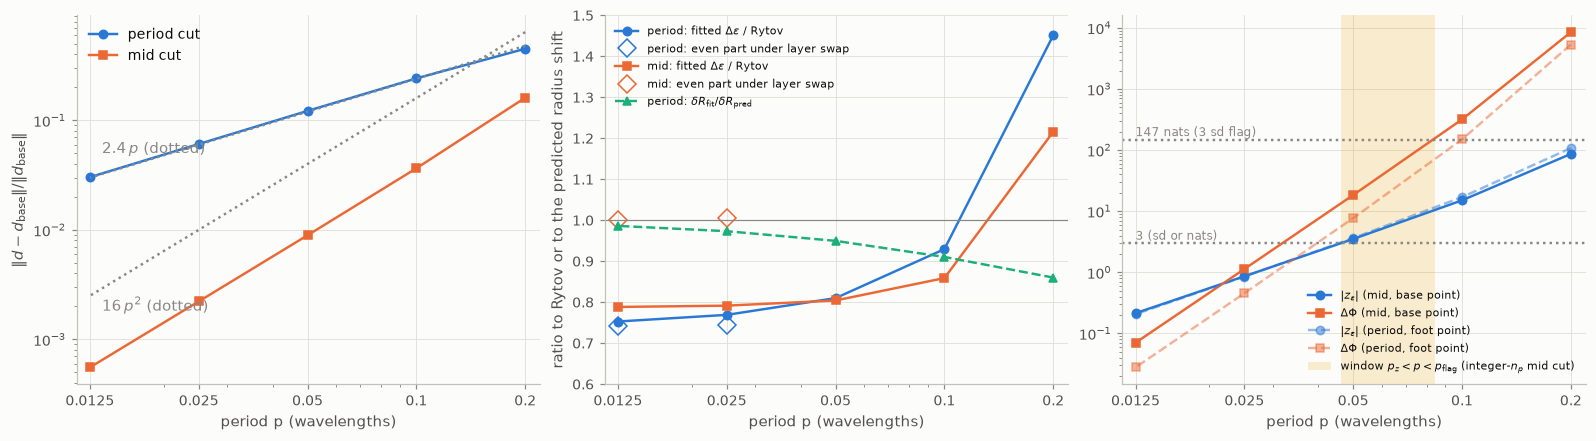

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(14.4, 3.9))
for j, (cut, mk) in enumerate((("period", "o"), ("mid", "s"))):
    ax[0].loglog(pv, [ROW[cut][n]["raw"] for n in NPS], mk + "-", color=CAT[j], label=f"{cut} cut")
ax[0].loglog(pv, 2.4 * pv, ":", color=MUTED); ax[0].loglog(pv, 16 * pv**2, ":", color=MUTED)
ax[0].text(0.0135, 0.05, r"$2.4\,p$ (dotted)", color=MUTED); ax[0].text(0.0135, 0.0018, r"$16\,p^2$ (dotted)", color=MUTED)
ax[0].set_xlabel("period p (wavelengths)"); ax[0].set_ylabel(r"$\|d-d_{\rm base}\|/\|d_{\rm base}\|$"); ax[0].legend()
for j, (cut, mk) in enumerate((("period", "o"), ("mid", "s"))):
    ax[1].semilogx(pv, [ROW[cut][n]["deps"] / ROW[cut][n]["rytov"] for n in NPS], mk + "-", color=CAT[j], label=rf"{cut}: fitted $\Delta\varepsilon$ / Rytov")
    ax[1].semilogx(pv[3:], [CTRL[(cut, n)]["E"] / CTRL[(cut, n)]["c0"]["rytov"] for n in (40, 80)], "D", color=CAT[j], mfc="none", ms=8, label=f"{cut}: even part under layer swap")
ax[1].semilogx(pv, [ROW["period"][n]["dRfit"] / ROW["period"][n]["dRpred"] for n in NPS], "^--", color=CAT[2], label=r"period: $\delta R_{\rm fit}/\delta R_{\rm pred}$")
ax[1].axhline(1.0, color=MUTED, lw=0.8); ax[1].set_ylim(0.6, 1.5); ax[1].set_xlabel("period p (wavelengths)"); ax[1].legend(fontsize=7.5, loc="upper left")
pp = np.logspace(np.log10(0.0125), np.log10(0.2), 50)
ax[2].loglog(pv, [abs(ROW["mid"][n]["base"]["z"]) for n in NPS], "o-", color=CAT[0], label=r"$|z_\varepsilon|$ (mid, base point)")
ax[2].loglog(pv, [ROW["mid"][n]["base"]["dphi"] for n in NPS], "s-", color=CAT[1], label=r"$\Delta\Phi$ (mid, base point)")
ax[2].loglog(pv, [abs(ROW["period"][n]["foot"]["z"]) for n in NPS], "o--", color=CAT[0], alpha=0.5, label=r"$|z_\varepsilon|$ (period, foot point)")
ax[2].loglog(pv, [ROW["period"][n]["foot"]["dphi"] for n in NPS], "s--", color=CAT[1], alpha=0.5, label=r"$\Delta\Phi$ (period, foot point)")
ax[2].axhline(3.0, color=MUTED, ls=":"); ax[2].axhline(FLAG, color=MUTED, ls=":"); ax[2].text(0.0125, FLAG * 1.15, "147 nats (3 sd flag)", color=MUTED, fontsize=8); ax[2].text(0.0125, 3.4, "3 (sd or nats)", color=MUTED, fontsize=8)
ax[2].axvspan(p_z, p_flag, color=CAT[3], alpha=0.18, lw=0, label=r"window $p_z<p<p_{\rm flag}$ (integer-$n_p$ mid cut)")
ax[2].set_xlabel("period p (wavelengths)"); ax[2].legend(fontsize=7.5, loc="lower right")
ax[1].set_ylabel("ratio to Rytov or to the predicted radius shift")
PT = [0.0125, 0.025, 0.05, 0.1, 0.2]
for a_ in ax: a_.set_xticks(PT, [f"{t:g}" for t in PT]); a_.xaxis.set_minor_formatter(NullFormatter()); a_.set_xlim(0.0115, 0.22)
plt.show()

*Figure 3.* Left: raw relative error of the data against the $(\bar\varepsilon,R_D)$ disk, $\propto p$ for the period cut and $\propto p^2$ for the mid cut. Middle: fitted $\Delta\varepsilon$ over the Rytov term for both cuts (filled), the part that is even under swapping the layer permittivities for $n_p=40,80$ (open diamonds; see the controls), and the radius-shift ratio $\delta R_{\rm fit}/\delta R_{\rm pred}$ for the period cut. Right: $|z_\varepsilon|$ and $\Delta\Phi$ against $p$ for the mid cut (base point) and the period cut (foot point), with the levels 3 and 147 and, shaded, the interval $p_z<p<p_{\rm flag}$ from the log-log laws (valid for the integer-$n_p$ mid-cut family only).

**Reading the outputs.** *Termination.* For the period cut the fitted radius shift over the predicted $-0.15p$ is $0.860,\ 0.911,\ 0.950,\ 0.973,\ 0.986$ for $n_p=5,\ldots,80$; the deficit ($0.0267$ at $p=0.025$, $0.0137$ at $p=0.0125$) falls with $p$; deficit$/p=0.70,\ 0.89,\ 1.01,\ 1.07,\ 1.10$ is still drifting at the smallest $p$, so 'proportional to $p$' is a trend. A fit of $a\,p+b\,p^2$ on $n_p=10$ to $80$ gives $a=1.12$, $b=-2.25$ with a largest relative residual of $0.7\%$: the deficit is consistent with an $O(p)$ relative correction to the radius shift, about $1.1p$, whose origin (a second-order effect of the shift, or a boundary term) is not identified here. For the mid cut $\delta R_{\rm fit}/p=0.0503,\ 0.0215,\ 0.0104,\ 0.0052,\ 0.0026$ over $p=0.2,\ldots,0.0125$ in the table, i.e. $\delta R_{\rm fit}=O(p^2)$ (the last two shifts have ratio $0.2495$). The raw error slopes over $n_p=10\ldots80$ are $0.9997$ and $2.013$. *First order against the nonlinear fit.* For $p\le0.05$ the first-order $z$ agrees with the noise-free nonlinear fit to $1.6\times10^{-3}$ and $\Delta\Phi$ to $8.9\times10^{-3}$ (period cut at the foot point, mid cut at the base point); linearizing the period cut at the base point instead overshoots $\Delta\Phi$ by a factor $102$ at $p=0.1$ and $129$ at $p=0.025$ (base-point $z=2.1$ against the foot-point $0.851$). *Scaling and the law.* For the mid cut the slopes over $n_p=10\ldots80$ are $2.042$ for $z$ and $4.043$ for $\Delta\Phi$, $\alpha\to18.01^\circ$ and $c=1.495,\ 1.523,\ 1.530$ at $n_p=20,\ 40,\ 80$; the identity $c_{\rm geom}=c_{\rm direct}$ holds to $2\times10^{-14}$ in every case.

**Detectability windows (mid cut, integer $n_p$).** Log-log laws through $n_p=20,40,80$ give $\Delta\Phi=3$ at $p_{3\rm nat}=0.0318$, $|z_\varepsilon|=3$ at $p_z=0.0463$, $\Delta\Phi=147$ at $p_{\rm flag}=0.0840$. These windows describe the *integer-$n_p$ mid-cut family*, where the core phase and the outer phase coincide; they are valid in the evaluated range $p\le1/12$ and shift with the core phase (below). The ordering $p_{3\rm nat}<p_z<p_{\rm flag}$ is not an accident of the numbers: with constant $c$, $\Delta\Phi=3$ means $z=\sqrt{3/c}=1.4<3$ and $\Delta\Phi=147$ means $z=\sqrt{147/c}=9.8>3$, which holds whenever $c\in(3/9,\,147/9)=(0.33,\,16.3)$, and $c=1.53$ does. The windows reproduce the values $(0.032,0.046,0.084)$ of a preliminary calculation to $0.7\%$. Because both criteria are expectations, the first table evaluates $z$ and $\Delta\Phi$ directly and gives the probability that the flag fires, $P(\tfrac12\chi'^2_{4798}(2\Delta\Phi)>2400+147)$ for the linear model (noncentral $\chi^2$), next to the shifted form $P(\tfrac12\chi^2_{4800}+\Delta\Phi>2547)$ and the same with the misfit of the noise-free nonlinear fit. At $p=1/22$: $z=2.89$ (nonlinear $2.88$), $\Delta\Phi=12.5$, $P=0.003$; at $p=1/15$: $z=6.35$, $\Delta\Phi=59.2$, $P=0.040$; at $p=1/12$: $z=10.15$, $\Delta\Phi=148.05$, $P=0.498$ ($0.520$ with the nonlinear $\Delta\Phi=151.0$): at $\Delta\Phi=147$ the flag fires about half the time. *Monte Carlo.* With noisy data, a nonlinear fit and the flag on $\Phi$, 2000 draws at $p=1/15$ give $83$ flags ($0.0415$; exact 99% interval $[0.031,\,0.054]$ against the predicted $0.040$, binomial $p$-value $0.65$), and $400$ draws at $p=1/12$ give $225$ ($0.5625$; $[0.497,\,0.627]$): the first-order prediction $0.498$ lies at the lower edge of that interval (two-sided $p$-value $0.01$) and the prediction with the nonlinear misfit, $0.520$, inside it ($p=0.10$). A check with only 150 draws at $p=1/15$ would have a tolerance wider than the predicted probability and could not fail; this one can (its interval half-width is $0.012$ against $0.040$). *Which target.* The second table in that cell asks what the fitted $\Delta\varepsilon$ is an estimate of. As an estimator of the volume average $\langle\varepsilon\rangle$ the error is $\Delta\varepsilon$ itself, $0.80,\,0.82,\,0.84$ times Rytov for the layer order of the text and $1.24,\,1.26,\,1.29$ for the swapped order at $p=1/22,\,1/15,\,1/12$, which is $z=2.89,\,6.35,\,10.15$ sd and exceeds 3 sd from $p_z$ (reading (a)). As an estimator of $\varepsilon_{\rm eff}(k_0)=\langle\varepsilon\rangle+{\rm Rytov}$ the standardized error $(\Delta\varepsilon-{\rm Rytov})/{\rm sd}$ is $-0.72,\,-1.41,\,-1.99$ and $+0.85,\,+2.03,\,+3.53$ (reading (b)): within about 2 sd up to $p_{\rm flag}$ for this structure and $3.5$ sd at $p_{\rm flag}$ for the swapped one. So up to $p\approx0.067$ the composition the fit reports is the second-order effective permittivity, not the volume average, and the misfit flag fires in at most $4\%$ of draws: the fit reports $\varepsilon_{\rm eff}(k_0)$, not $\langle\varepsilon\rangle$, before the layering is detectable. This is about the interpretation of the number, not a silent failure of the homogeneous model. *The window is not general.* At $p=0.07$ ($n_p=14.29$, the structure of section 5, core phase $0.75-14.29\bmod1=0.46$) $z=4.63$, $\Delta\Phi=86.5$ and $P=0.113$, and the standardized error against $\langle\varepsilon\rangle+{\rm Rytov}$ is $-3.93$ and $+4.68$; at $n_p=15.25,\ 15.5,\ 15.75$ (near $p=1/15$, different core phases) $z=4.47,\ 2.73,\ 4.17$, $\Delta\Phi=60.2,\ 87.2,\ 52.8$, $P=0.041,\ 0.116,\ 0.030$ and the swapped order is $3.61,\ 5.11,\ 3.36$ sd from $\langle\varepsilon\rangle+{\rm Rytov}$ (the odd boundary term of the controls below). Extrapolating the integer-family windows to $p=0.07$ with $z\propto p^2$ would give $z=7.0$ and misses all of this; the windows are not stated beyond the evaluated range or for other core phases. A criterion that is a $\Delta\Phi=3$ nat level on the misfit would be reached at $p\approx0.032$ in the integer family; no evidence ratio against a named richer model is computed here.

## 4. A lattice in the testbed: the rotational selection rule

The ch15 acquisition is invariant under rotation by $18^\circ$: with 40 transmitters ($9^\circ$ apart) and 60 receivers ($6^\circ$ apart), the rotation maps transmitter $j\to j+2$ and receiver $l\to l+3$, a cyclic group $C_{20}$ acting on the data by the roll $R^j$. The real isotypic projectors are $Q_k=\frac{c_k}{20}\sum_{j}\cos(2\pi jk/20)R^j$, $c_0=c_{10}=1$, $c_k=2$ otherwise, $k=0\ldots10$; they are mutually orthogonal and sum to the identity. Rotation by $90^\circ=5\times18^\circ$ is the roll $(j,l)\to(j+10,l+15)$. Two consequences, both with conditions.

1. The exact Mie data of a *centered* disk lie in $Q_0$ (rotation invariant), and so do the $\varepsilon$ and $R$ tangents; the tangents in $c_x,c_y$ lie in $Q_1$ (vector representation). This holds for the exact rotation-invariant Mie model; the testbed's pixelated tangents are only $C_4$-covariant and would break it. It requires scalar (white) whitening, so that the $Q_k$ stay orthogonal in the whitened inner product, and tangents accurate beyond finite differences at step $10^{-6}$ (analytic tangents, or central differences at step $10^{-5}$ with tolerance $10^{-8}$).
2. The data of a $C_4$-invariant object satisfy $R^5d=d$, i.e. lie in the sectors with $5k\equiv0\ (\mathrm{mod}\ 20)$, $k\in\{0,4,8\}$. A square lattice of rods with a rod at the origin, painted on an even grid centered at the origin and shared with the model, the antenna rings and the rotation, is exactly $C_4$ invariant, so $\delta=d_{\rm lattice}-d_{\rm model}\in Q_0\oplus Q_4\oplus Q_8$ when the model's base data are in $Q_0$. Then $Q_4\delta+Q_8\delta$ is orthogonal to every tangent of the model $(\varepsilon,R,c_x,c_y)$: it raises $\Delta\Phi$ and cannot bias the estimate. This generalizes the $D_2$ rule of DESIGN 15.2 from reflections to rotations.

The experiment: rods of permittivity 4 and radius $0.3p$ on a square lattice of period $p\in\{0.5,0.33,0.25\}$, centers inside $R_D=1$ (13, 29, 49 rods), on the testbed grid $n=128$, side 2.5 ($h=0.0195$; at $p=0.25$ a rod is 3.8 pixels in radius), solved by GMRES (restart 100, tolerance $10^{-10}$). The base permittivity is `lattice_disk_eps_bar`, the area average counting whole rods (the nominal $f\varepsilon$ average of the cell would differ). The floor is the testbed's own error for the homogeneous disk of that permittivity against exact Mie. The cells check, before any interpretation: the tangent sectors (analytic and finite-difference), the exact $C_4$ invariance of the painted $\chi$, the solver residual, the sector content of the data, the orthogonality of $Q_4\delta+Q_8\delta$ to the tangents, and the equality $z(\delta)=z(Q_0\delta)$ (the last two, and the additivity of $\Delta\Phi$, follow from the first three and are labeled consistency checks).

In [18]:
t_lat = time.perf_counter()
st4 = ch15_setup(n=128, side=2.5)
fw4 = Forward(st4, tol=1e-10, restart=100, maxiter=30)
txg, rxg = st4.antennas.tx, st4.antennas.rx
check("the testbed antennas are the ones used above (tx, rx identical)", float(np.abs(txg - tx).max() + np.abs(rxg - rx).max()), 1e-15)
QK = [sc.c20_projector(k) for k in range(11)]
# tangent sectors of the exact Mie model, centered disk: analytic and central differences with step 1e-5
pc = [ebar, RD, 0.0, 0.0]
Ta = sc.disk_tangents(pc, tx, rx)
Tf = sc.disk_tangents(pc, tx, rx, jac="fd", step=1e-5)
sec = lambda T: (max(rel(QK[0](T[i]), T[i]) for i in (0, 1)), max(rel(QK[1](T[i]), T[i]) for i in (2, 3)))
print(f"tangent sectors, analytic:   ||(I-Q_0) d_eps, d_R||/||.|| = {sec(Ta)[0]:.1e},  ||(I-Q_1) d_cx, d_cy||/||.|| = {sec(Ta)[1]:.1e}")
print(f"tangent sectors, central FD: ||(I-Q_0) d_eps, d_R||/||.|| = {sec(Tf)[0]:.1e},  ||(I-Q_1) d_cx, d_cy||/||.|| = {sec(Tf)[1]:.1e}")
check("tangents d_eps, d_R lie in Q_0 (analytic, rel); tolerance 1e-8", sec(Ta)[0], 1e-8)
check("tangents d_cx, d_cy lie in Q_1 (analytic, rel)", sec(Ta)[1], 1e-8)
check("same with central differences, step 1e-5, Q_0 sector", sec(Tf)[0], 1e-8)
check("same with central differences, step 1e-5, Q_1 sector", sec(Tf)[1], 1e-8)
check("analytic vs central-difference tangents (max rel)", max(rel(Ta[i], Tf[i]) for i in range(4)), 1e-6)

LAT = {}
for pl in (0.5, 0.33, 0.25):
    chi = sc.lattice_disk_chi(st4.grid, RD, pl)
    c4 = float(np.abs(chi - np.rot90(chi)).max())
    check(f"painted lattice chi is exactly C4-invariant before solving, p = {pl} (max |chi - rot90 chi|)", c4, 1e-15)
    d, u = fw4(chi)
    d = np.asarray(d)
    res = float(np.max(fw4.residual(chi, u)))
    eb = sc.lattice_disk_eps_bar(RD, pl)
    dm = sc.mie_disk(eb, RD, (0, 0), tx, rx)
    dcyl = np.asarray(fw4(cylinder(st4.grid, RD, eb))[0])
    LAT[pl] = dict(chi=chi, d=d, res=res, eb=eb, dm=dm, floor=float(np.linalg.norm(dcyl - dm)), nrod=len(sc.lattice_disk_rods(RD, pl)))
print(f"six forward solves at n = 128 (lattice and homogeneous-cylinder floor, three periods) took {time.perf_counter() - t_lat:.1f} s")

PASS  the testbed antennas are the ones used above (tx, rx identical): got 0, target 0, |diff| 0.00e+00 <= 1e-15
tangent sectors, analytic:   ||(I-Q_0) d_eps, d_R||/||.|| = 2.6e-15,  ||(I-Q_1) d_cx, d_cy||/||.|| = 2.8e-15
tangent sectors, central FD: ||(I-Q_0) d_eps, d_R||/||.|| = 1.5e-12,  ||(I-Q_1) d_cx, d_cy||/||.|| = 5.1e-10
PASS  tangents d_eps, d_R lie in Q_0 (analytic, rel); tolerance 1e-8: got 2.6097e-15, target 0, |diff| 2.61e-15 <= 1e-08
PASS  tangents d_cx, d_cy lie in Q_1 (analytic, rel): got 2.8334e-15, target 0, |diff| 2.83e-15 <= 1e-08
PASS  same with central differences, step 1e-5, Q_0 sector: got 1.45041e-12, target 0, |diff| 1.45e-12 <= 1e-08
PASS  same with central differences, step 1e-5, Q_1 sector: got 5.11467e-10, target 0, |diff| 5.11e-10 <= 1e-08
PASS  analytic vs central-difference tangents (max rel): got 6.37647e-08, target 0, |diff| 6.38e-08 <= 1e-06
PASS  painted lattice chi is exactly C4-invariant before solving, p = 0.5 (max |chi - rot90 chi|): got 0, targ

PASS  painted lattice chi is exactly C4-invariant before solving, p = 0.33 (max |chi - rot90 chi|): got 0, target 0, |diff| 0.00e+00 <= 1e-15


PASS  painted lattice chi is exactly C4-invariant before solving, p = 0.25 (max |chi - rot90 chi|): got 0, target 0, |diff| 0.00e+00 <= 1e-15


six forward solves at n = 128 (lattice and homogeneous-cylinder floor, three periods) took 7.9 s


In [19]:
rows, LR = [], {}
for pl, L in LAT.items():
    d, dm, eb = L["d"], L["dm"], L["eb"]
    sL = sc.noise_level(dm, 30.0)
    D4 = sc.disk_jacobian([eb, RD, 0.0, 0.0], tx, rx, sL)                    # model: disk (eps, R, cx, cy)
    delta = sc.whitened_delta(d, dm, sL)
    a = det.analyze_error(D4, delta)
    fr = sc.c20_fractions(d - dm)                                              # fractions of ||delta||^2 by sector k = 0..10
    d48 = QK[4](d - dm) + QK[8](d - dm)
    d0_ = QK[0](d - dm)
    w48, w0 = sc.whiten(d48, sL), sc.whiten(d0_, sL)
    rest = (d - dm) - d48 - d0_
    sector = float(np.linalg.norm(d - QK[0](d) - QK[4](d) - QK[8](d)) / np.linalg.norm(d))
    z_full, z_q0 = a["z"], float(a["w_hat"] @ w0)
    orth = float(np.linalg.norm(D4.T @ w48) / (np.linalg.norm(D4, 2) * np.linalg.norm(w48)))
    dphi48 = 0.5 * float(w48 @ w48)
    dphi0 = det.analyze_error(D4, w0)["dphi"]
    LR[pl] = dict(a=a, fr=fr, sector=sector, zrel=abs(z_full - z_q0) / abs(z_full), orth=orth, dphi48=dphi48, dphi0=dphi0, ratio=float(np.linalg.norm(d - dm) / L["floor"]),
                  dp=a["dp"] / a["sigma"], res=L["res"], rest=float(np.linalg.norm(rest) / np.linalg.norm(d - dm)), eb=eb, nrod=L["nrod"])
    rows.append((pl, L["nrod"], eb, fr[0], fr[4], fr[8], 1 - fr[0] - fr[4] - fr[8], a["z"], a["dp"][1] / a["sigma"][1], a["dphi"], dphi0, dphi48, LR[pl]["ratio"]))
table(["p", "rods", "eps base", "Q_0", "Q_4", "Q_8", "other", "z_eps", "z_R", "dPhi", "dPhi(Q_0 part)", "dPhi(Q_4+Q_8)", "|delta|/floor"], rows,
      [".2f", "d", ".4f", ".3f", ".3f", ".3f", ".1e", ".1f", ".1f", ".4g", ".4g", ".4g", ".0f"])
print(f"model-center biases in sd (cx, cy): " + "; ".join(f"p = {pl}: {LR[pl]['dp'][2]:.2e}, {LR[pl]['dp'][3]:.2e}" for pl in LR))
print(f"flag level {FLAG:.1f} nats; solver residuals: " + ", ".join(f"{LR[pl]['res']:.1e}" for pl in LR))
for pl in LR:
    check(f"p = {pl}: GMRES residual of the lattice solve (max over transmitters)", LR[pl]["res"], 1e-8)
    check(f"p = {pl}: lattice data are C4-invariant, ||(I - Q_0 - Q_4 - Q_8) d||/||d||", LR[pl]["sector"], 1e-8)
    check(f"p = {pl}: [consistency] |z(delta) - z(Q_0 delta)|/|z(delta)|: follows from the sector check and the tangents in Q_0 + Q_1", LR[pl]["zrel"], 1e-8)
    check(f"p = {pl}: [consistency] the Q_4 + Q_8 part of delta is orthogonal to all four model tangents (normalized)", LR[pl]["orth"], 1e-8)
    check_in(f"p = {pl}: signal above the grid floor, ||delta||/floor > 3", LR[pl]["ratio"], 3.0, 1e6)
    check(f"p = {pl}: [consistency] DeltaPhi = DeltaPhi(Q_0 part) + DeltaPhi(Q_4 + Q_8 part) (rel)", abs(LR[pl]["a"]["dphi"] / (LR[pl]["dphi0"] + LR[pl]["dphi48"]) - 1), 1e-8)
# the check that delta has no components outside Q_0, Q_4, Q_8 is the same statement as the sector check on d (the model data lie in Q_0), so it is printed, not asserted
print("delta outside Q_0, Q_4, Q_8, relative: " + ", ".join(f"{LR[pl]['rest']:.1e}" for pl in LR) + "  (equal to the data sector check up to the model's own Q_0 content)")

   p  rods  eps base    Q_0    Q_4    Q_8     other   z_eps     z_R       dPhi  dPhi(Q_0 part)  dPhi(Q_4+Q_8)  |delta|/floor
0.50    13    1.8775  0.436  0.361  0.203  -2.5e-16  -150.2   -24.5  8.991e+05       3.638e+05      5.352e+05            258
0.33    29    1.8527  0.606  0.096  0.297   5.6e-17   343.2  -123.7  1.436e+06        8.27e+05      6.087e+05            346
0.25    49    1.8269  0.629  0.053  0.319  -2.2e-16   413.2  -157.5  1.915e+05       6.187e+04      1.296e+05            173
model-center biases in sd (cx, cy): p = 0.5: 1.57e-09, -2.22e-10; p = 0.33: 1.39e-09, 6.89e-10; p = 0.25: -1.39e-09, 1.29e-09
flag level 147.0 nats; solver residuals: 1.0e-10, 9.4e-11, 8.6e-11
PASS  p = 0.5: GMRES residual of the lattice solve (max over transmitters): got 9.97223e-11, target 0, |diff| 9.97e-11 <= 1e-08
PASS  p = 0.5: lattice data are C4-invariant, ||(I - Q_0 - Q_4 - Q_8) d||/||d||: got 2.32011e-11, target 0, |diff| 2.32e-11 <= 1e-08
PASS  p = 0.5: [consistency] |z(delta) - z(Q_0

In [20]:
# the same statement for the nonlinear fit (eps, R, cx, cy free): removing the Q_4 + Q_8 part of the error changes DeltaPhi and nothing else.
# The misfit is of order 10^5 to 10^6 nats here, and Gauss-Newton converges slowly: 100 iterations (15 stop short by up to 1.4 sd at p = 0.33).
rows = []
for pl, L in LAT.items():
    d, dm, eb = L["d"], L["dm"], L["eb"]
    sL = sc.noise_level(dm, 30.0)
    d48 = QK[4](d - dm) + QK[8](d - dm)
    pa, Da, ra = sc.fit_disk(d, tx, rx, [eb, RD, 0.0, 0.0], sL, free=("eps", "R", "cx", "cy"), iters=100)
    pb, Db_, rb = sc.fit_disk(d - d48, tx, rx, [eb, RD, 0.0, 0.0], sL, free=("eps", "R", "cx", "cy"), iters=100)
    sg = np.sqrt(np.diag(np.linalg.inv(Da.T @ Da)))
    # two other starts: the center displaced (breaks the symmetry the first start sits on) and (eps, R) displaced
    pc1, _, rc1 = sc.fit_disk(d, tx, rx, [eb, RD, 0.03, -0.02], sL, free=("eps", "R", "cx", "cy"), iters=100)
    pc2, _, rc2 = sc.fit_disk(d, tx, rx, [eb + 0.3, 1.01 * RD, 0.0, 0.0], sL, free=("eps", "R", "cx", "cy"), iters=100)
    LR[pl].update(pa=pa, pb=pb, sg=sg, phiA=0.5 * float(ra @ ra), phiB=0.5 * float(rb @ rb), pc1=pc1, pc2=pc2, phiC1=0.5 * float(rc1 @ rc1), phiC2=0.5 * float(rc2 @ rc2))
    rows.append((pl, (pa[0] - eb) / sg[0], LR[pl]["a"]["z"], (pa[1] - RD) / sg[1], pa[2] / sg[2], pa[3] / sg[3], np.abs(pa - pb).max() / sg.min(), LR[pl]["phiA"] - LR[pl]["phiB"], LR[pl]["dphi48"]))
table(["p", "eps fit z (NL)", "z first order", "R fit (sd)", "cx fit (sd)", "cy fit (sd)", "max|fit(d) - fit(d - Q48)|/sd", "dPhi_NL(d) - dPhi_NL(d - Q48)", "dPhi(Q4+Q8) first order"], rows,
      [".2f", ".1f", ".1f", ".1f", ".1e", ".1e", ".1e", ".5g", ".5g"])
for pl in LR:
    check(f"p = {pl}: the fit does not feel the Q_4 + Q_8 part: parameters with and without it differ by (max, in sd)", float(np.abs(LR[pl]["pa"] - LR[pl]["pb"]).max() / LR[pl]["sg"].min()), 1e-6)
    check(f"p = {pl}: ... and the misfit differs by exactly its first-order DeltaPhi(Q_4 + Q_8) (rel)", abs((LR[pl]["phiA"] - LR[pl]["phiB"]) / LR[pl]["dphi48"] - 1), 1e-8)
    check(f"p = {pl}: a start with the center displaced by (0.03, -0.02) returns to the symmetric fit (max parameter difference, in sd)", float(np.abs(LR[pl]["pc1"] - LR[pl]["pa"]).max() / LR[pl]["sg"].min()), 1e-6)
    check(f"p = {pl}: a start with (eps, R) displaced by (+0.3, +1%) returns to the same fit (max parameter difference, in sd)", float(np.abs(LR[pl]["pc2"] - LR[pl]["pa"]).max() / LR[pl]["sg"].min()), 1e-6)
    check(f"p = {pl}: ... with the same misfit (rel, both displaced starts)", max(abs(LR[pl]["phiC1"] / LR[pl]["phiA"] - 1), abs(LR[pl]["phiC2"] / LR[pl]["phiA"] - 1)), 1e-8)
print("displaced starts, max parameter difference in posterior sd: " + "; ".join(f"p = {pl}: {np.abs(LR[pl]['pc1'] - LR[pl]['pa']).max() / LR[pl]['sg'].min():.1e}, {np.abs(LR[pl]['pc2'] - LR[pl]['pa']).max() / LR[pl]['sg'].min():.1e}" for pl in LR))
print("fitted center (cx, cy) in sd from the symmetric start: " + "; ".join(f"p = {pl}: {LR[pl]['pa'][2] / LR[pl]['sg'][2]:.1e}, {LR[pl]['pa'][3] / LR[pl]['sg'][3]:.1e}" for pl in LR))

   p  eps fit z (NL)  z first order  R fit (sd)  cx fit (sd)  cy fit (sd)  max|fit(d) - fit(d - Q48)|/sd  dPhi_NL(d) - dPhi_NL(d - Q48)  dPhi(Q4+Q8) first order
0.50          -404.7         -150.2        92.8      2.1e-09     -1.3e-10                        1.5e-12                     5.3521e+05               5.3521e+05
0.33          1057.4          343.2      -603.2      7.3e-10      8.7e-10                        8.9e-11                     6.0873e+05               6.0873e+05
0.25           432.8          413.2      -129.2     -2.6e-09      2.1e-09                        3.1e-11                     1.2958e+05               1.2958e+05
PASS  p = 0.5: the fit does not feel the Q_4 + Q_8 part: parameters with and without it differ by (max, in sd): got 1.48994e-12, target 0, |diff| 1.49e-12 <= 1e-06
PASS  p = 0.5: ... and the misfit differs by exactly its first-order DeltaPhi(Q_4 + Q_8) (rel): got 6.66134e-16, target 0, |diff| 6.66e-16 <= 1e-08
PASS  p = 0.5: a start with the center displ

In [21]:
# the multilayer series that every ring result rests on, against the testbed forward solver: a two-layer ring (radii 0.5, 1; eps 3, 1.5) painted on the n = 128 grid
# with 8 x 8 supersampling, compared with the exact series at the level of the homogeneous disk's grid floor
def paint_rings(grid, radii, eps, ss=8):
    X, Y = grid.centers()
    h = grid.h
    off = (np.arange(ss) + 0.5) / ss - 0.5
    chi = np.zeros_like(X)
    for dx in off:
        for dy in off:
            r = np.hypot(X + dx * h, Y + dy * h)
            e, lo = np.ones_like(X), 0.0
            for R_, ev in zip(radii, eps):
                e = np.where((r >= lo) & (r < R_), ev, e)
                lo = R_
            chi += e - 1.0
    return chi / ss**2


dex2 = sc.exact_data(tx, rx, [0.5, 1.0], [3.0, 1.5])
d2 = np.asarray(fw4(paint_rings(st4.grid, [0.5, 1.0], [3.0, 1.5]))[0])
dh_ex = sc.mie_disk(ebar, RD, (0, 0), tx, rx)
dh = np.asarray(fw4(paint_rings(st4.grid, [1.0], [ebar]))[0])
e_ring, e_disk = rel(d2, dex2), rel(dh, dh_ex)
print(f"testbed forward solve (n = 128) vs exact data: two-layer ring {e_ring:.2e}; the painted homogeneous disk of radius 1 (the grid floor) {e_disk:.2e}")
check_in("multilayer series vs the testbed solver, two-layer ring: relative difference is at most the grid floor of a homogeneous disk painted the same way (ratio <= 1.5)", e_ring / e_disk, 0.0, 1.5)

testbed forward solve (n = 128) vs exact data: two-layer ring 4.88e-03; the painted homogeneous disk of radius 1 (the grid floor) 7.64e-03
PASS  multilayer series vs the testbed solver, two-layer ring: relative difference is at most the grid floor of a homogeneous disk painted the same way (ratio <= 1.5): got 0.638467, required in [0, 1.5]


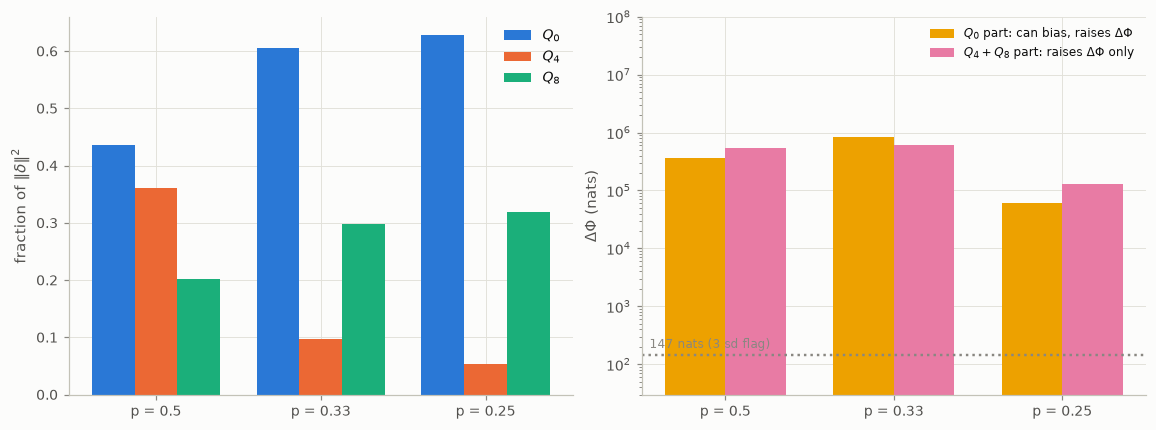

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(10.4, 3.8))
x = np.arange(3); wd = 0.26
for j, k in enumerate((0, 4, 8)):
    ax[0].bar(x + (j - 1) * wd, [LR[pl]["fr"][k] for pl in LR], wd, color=CAT[j], label=f"$Q_{k}$")
ax[0].set_xticks(x, [f"p = {pl}" for pl in LR]); ax[0].set_ylabel(r"fraction of $\|\delta\|^2$"); ax[0].legend()
for j, (lab, key) in enumerate(((r"$Q_0$ part: can bias, raises $\Delta\Phi$", "dphi0"), (r"$Q_4+Q_8$ part: raises $\Delta\Phi$ only", "dphi48"))):
    ax[1].bar(x + (j - 0.5) * 0.36, [LR[pl][key] for pl in LR], 0.36, color=CAT[j + 3], label=lab)
ax[1].set_yscale("log"); ax[1].set_ylim(30, 1e8); ax[1].axhline(FLAG, color=MUTED, ls=":"); ax[1].text(-0.45, FLAG * 1.3, "147 nats (3 sd flag)", color=MUTED, fontsize=8)
ax[1].set_xticks(x, [f"p = {pl}" for pl in LR]); ax[1].set_ylabel(r"$\Delta\Phi$ (nats)"); ax[1].legend(fontsize=8, loc="upper right")
plt.show()

*Figure 4.* Left: fractions of $\|\delta\|^2$ in the rotation sectors $Q_0,Q_4,Q_8$ for the three lattices (the other sectors are empty to $10^{-11}$). Right: $\Delta\Phi$ split into the part from $Q_0$ (which can accompany a bias) and from $Q_4\oplus Q_8$ (which cannot), against the 147-nat flag level.

**Reading the outputs.** The tangents of the Mie model are in their sectors to $2.6\times10^{-15}$ ($Q_0$) and $2.8\times10^{-15}$ ($Q_1$) analytically, and to $1.5\times10^{-12}$ and $5.1\times10^{-10}$ with central differences at step $10^{-5}$. The painted $\chi$ is exactly $C_4$ invariant (difference $0$) and the lattice data lie in $Q_0\oplus Q_4\oplus Q_8$ to $2\times10^{-11}$ to $4\times10^{-11}$ (relative; solver residual $10^{-10}$). The fractions of $\|\delta\|^2$ in $(Q_0,Q_4,Q_8)$ are $(0.436,0.361,0.203)$, $(0.606,0.096,0.297)$ and $(0.629,0.053,0.319)$ for $p=0.5,0.33,0.25$. The error is $258$, $346$ and $173$ times the grid floor. The statements of the rule hold to roundoff: $|z(\delta)-z(Q_0\delta)|/|z(\delta)|\le10^{-15}$; $\|D^T w_{48}\|$ relative to $\|D\|\|w_{48}\|$ is $\le2.6\times10^{-16}$; $\Delta\Phi=\Delta\Phi(Q_0\text{ part})+\Delta\Phi(Q_4{+}Q_8)$ to $10^{-15}$. These three are consistency checks of the numerics (they follow from the sector content of the data and the tangents, and would pass whatever the physics), and are labeled so; the content is in the sector checks, the tangent-sector checks and the nonlinear fits below. $\Delta\Phi(Q_4{+}Q_8)=5.35\times10^5$, $6.09\times10^5$, $1.30\times10^5$ nats against the flag level of $147$. The nonlinear fit with $(\varepsilon,R,c_x,c_y)$ free (100 Gauss-Newton iterations: the misfit is $10^5$ to $10^6$ nats and 15 iterations stop up to $1.4$ sd short at $p=0.33$), on the data with and without the $Q_4\oplus Q_8$ part, returns parameters that differ by at most $8.9\times10^{-11}$ posterior sd, and the misfit differs by exactly $\Delta\Phi(Q_4{+}Q_8)$ to $1.8\times10^{-15}$. Starting from the symmetric point the center cannot move (the iterates stay in the symmetric subspace; it ends at $\le3\times10^{-9}$ sd), which is why that is not evidence that the symmetric point is a minimum. Two further starts are: the center displaced by $(0.03,-0.02)$, which returns to the same fit to $7\times10^{-12}$ sd, and $(\varepsilon,R)$ displaced by $(+0.3,+1\%)$, which returns to $7\times10^{-11}$ sd with the same misfit to $10^{-15}$. So within these starts the nonlinear fit has a single minimum on the symmetric point, and the rotation-sector content that no rod pattern of $C_4$ symmetry can move into the model is pure misfit at the nonlinear level too. Two cautions. The first-order bias at the base point ($z_\varepsilon=-150,\ 343,\ 413$ at $p=0.5,\ 0.33,\ 0.25$) differs from the nonlinear one ($-405,\ 1057,\ 433$ sd) by factors of $2.7$ and $3.1$ at $p=0.5$ and $0.33$ and by $5\%$ at $p=0.25$; at hundreds of sd the linearization is not generally valid, so the first-order values are not estimates of the bias, only the exact decomposition holds (the nonlinear values come from fits that agree across the three starts, so they are minima of the misfit within those starts, not proven global minima). And the $Q_0$ part of the error ($44\%$ to $63\%$ of $\|\delta\|^2$) is a *different* statement, not covered by the rule: it is rod-pattern content that is rotationally symmetric and can be absorbed by $\varepsilon$ and $R$, or sit in the normal space. *Multilayer series.* The two-layer ring (radii $0.5,\ 1$; $\varepsilon=3,\ 1.5$) painted on this grid agrees with the exact multilayer data to $4.9\times10^{-3}$, below the $7.6\times10^{-3}$ of the painted homogeneous disk (the grid floor), and the series agrees with an independent $J/Y$ interface-matching recursion to $6\times10^{-14}$ ($n_p=5$) and $3\times10^{-14}$ ($n_p=20$) in section 3's setup.

## 5. An approximation-error model for the composition (rings, exact)

Following Kaipio and Somersalo, treat the termination as random: model the data as $y=d_{\rm model}(\theta)+\delta+n$ with $\delta\sim\mathcal N(\mu,C)$, estimate $\mu,C$ from an ensemble of errors, and use $\mu$ as a shifted mean and $C$ as an extra noise covariance. With whitened data and $\Sigma=I+C$ the linearized estimator is $\hat\theta=(D^T\Sigma^{-1}D)^{-1}D^T\Sigma^{-1}(e-\mu)$ for an error vector $e$, with covariance $(D^T\Sigma^{-1}D)^{-1}$; with $C=AA^T/(m-1)$ of rank $\le m-1$ the inverse is a Woodbury formula in the $m\times m$ matrix. The coverage of the nominal 90% interval for the composition $\bar\varepsilon=2.25$ of a held-out case with standardized error $z_i$ is $P(|\mathcal N(z_i,1)|\le1.645)$, computed without sampling.

The ensemble: $p=0.07$ ($n_p=14.29$), 64 ring structures whose cut phase $c$ is uniform in the outermost period (the profile phase at $R_D$ is fixed, so the core is whatever it is), 32 for estimation and 32 held out. Caution: the cuts move the radius by up to about $0.01$, i.e. $\sim10^2\sigma_R$, so linearization at the base point may be invalid for both naive and AEM coverage. Before computing coverage the cell compares, for four cuts $c=0,\ 0.25,\ 0.5,\ 0.75$ (the period cut and three others that span $X_0$), the linearized $z$ at the base point and at the profile foot point with the nonlinear fit, and if the base point fails by more than $0.1$ sd the AEM is built in the foot-point frame: the error vectors are the whitened residuals at the foot point (permittivity fixed at $\bar\varepsilon$, $R$ least squares per case), and the Jacobian is taken at the mean foot radius.

In [23]:
P5 = 0.07
NP5 = RD / P5
rng5 = np.random.default_rng(5)
cuts = rng5.uniform(0.0, 1.0, 64)
est, hold = np.arange(32), np.arange(32, 64)
t5 = time.perf_counter()
CUT = {}
for i, c in enumerate(cuts):
    d = sc.exact_data(tx, rx, *sc.rings(RD, NP5, f, e1, e2, float(c)))
    pf, Df, rf = sc.foot_point_R(d, tx, rx, ebar, RD, s0)                 # profile foot point: eps fixed at epsbar
    CUT[i] = dict(c=float(c), d=d, Rf=pf[1], Df=Df, rf=rf, delta_base=sc.whitened_delta(d, d0, s0))
print(f"{len(cuts)} ring structures, p = {P5} (n_p = {NP5:.3f}), {time.perf_counter() - t5:.1f} s")
# (a) linearized z against nonlinear fits for 4 held-out cuts spanning X0, including the period cut
rows = []
for c in (0.0, 0.25, 0.5, 0.75):
    d = sc.exact_data(tx, rx, *sc.rings(RD, NP5, f, e1, e2, c))
    zb = det.analyze_error(D0, sc.whitened_delta(d, d0, s0))
    pf, Df, rf = sc.foot_point_R(d, tx, rx, ebar, RD, s0)
    zf = det.analyze_error(Df, rf)
    p2, D2, r2 = sc.fit_disk(d, tx, rx, [ebar, RD], s0)
    zNL = (p2[0] - ebar) / zf["sigma"][0]
    rows.append((c, pf[1] - RD, zb["z"], zf["z"], zNL, abs(zb["z"] - zNL), abs(zf["z"] - zNL), zb["dphi"], zf["dphi"], 0.5 * float(r2 @ r2)))
table(["cut c", "dR foot", "z base", "z foot", "z NL fit", "|base - NL|", "|foot - NL|", "dPhi base", "dPhi foot", "dPhi NL"], rows,
      [".2f", ".3e", ".2f", ".2f", ".2f", ".2f", ".3f", ".4g", ".4g", ".4g"])
LIN = rows

64 ring structures, p = 0.07 (n_p = 14.286), 4.5 s


cut c     dR foot  z base  z foot  z NL fit  |base - NL|  |foot - NL|  dPhi base  dPhi foot  dPhi NL
 0.00  -9.789e-03   15.10    9.28      9.28         5.82        0.001       3745      35.79    35.81
 0.25   1.806e-04   13.19   13.18     13.20         0.01        0.025      90.05      90.14    90.02
 0.50   1.147e-02   19.40    3.94      3.93        15.47        0.008       2732      66.82    66.84
 0.75   1.016e-03    4.63    4.59      4.58         0.05        0.005      86.54      87.91    87.93


In [24]:
from scipy.stats import norm
Z90 = norm.ppf(0.95)
cover = lambda z: norm.cdf(Z90 - z) - norm.cdf(-Z90 - z)         # P(|N(z, 1)| <= 1.645): chance that the 90% interval covers when the standardized bias is z


def aem(frames, D, idx_est):
    """Approximation-error model in whitened data: mean mu and covariance C of the error vectors over the estimation set;
    estimator theta = (D^T S^-1 D)^-1 D^T S^-1 (e - mu), S = I + C, with Woodbury for S^-1. Returns a function e -> theta and the posterior sd of eps."""
    E = np.stack([frames[i] for i in idx_est], axis=1)                 # (4800, m)
    mu = E.mean(axis=1)
    A = E - mu[:, None]
    m = E.shape[1]
    Sinv = lambda V: V - A @ np.linalg.solve((m - 1) * np.eye(m) + A.T @ A, A.T @ V)      # (I + A A^T/(m-1))^-1 V
    M = D.T @ Sinv(D)
    cov = np.linalg.inv(M)
    est_fn = lambda e: cov @ (D.T @ Sinv(e - mu))
    return est_fn, float(np.sqrt(cov[0, 0])), mu


Rbar = float(np.mean([CUT[i]["Rf"] for i in est]))
Dbar = sc.disk_jacobian([ebar, Rbar], tx, rx, s0)
out = {}
for frame, vec, D in (("foot", lambda i: CUT[i]["rf"], Dbar), ("base", lambda i: CUT[i]["delta_base"], D0)):
    fr_ = {i: vec(i) for i in CUT}
    fn, sd_aem, mu = aem(fr_, D, est)
    sd_naive = float(np.sqrt(np.linalg.inv(D.T @ D)[0, 0]))
    z_naive = {i: float(det.analyze_error(CUT[i]["Df"], CUT[i]["rf"])["z"]) if frame == "foot" else float(det.analyze_error(D0, CUT[i]["delta_base"])["z"]) for i in CUT}
    z_aem = {i: float(fn(fr_[i])[0] / sd_aem) for i in CUT}
    out[frame] = dict(z_naive=z_naive, z_aem=z_aem, sd_ratio=sd_aem / sd_naive, mu_norm=float(np.linalg.norm(mu)))
    cn = lambda idx: float(np.mean([cover(z_naive[i]) for i in idx]))
    ca = lambda idx: float(np.mean([cover(z_aem[i]) for i in idx]))
    out[frame].update(cov_naive_hold=cn(hold), cov_aem_hold=ca(hold), cov_naive_est=cn(est), cov_aem_est=ca(est))
rows = [(fr_, o["cov_naive_hold"], o["cov_aem_hold"], o["cov_naive_est"], o["cov_aem_est"], o["sd_ratio"],
         float(np.median(np.abs([o["z_naive"][i] for i in hold]))), float(np.median(np.abs([o["z_aem"][i] for i in hold])))) for fr_, o in out.items()]
table(["frame", "naive held-out", "AEM held-out", "naive est. set", "AEM est. set", "sd(AEM)/sd(naive)", "median |z| naive", "median |z| AEM"], rows, ["s", ".3f", ".3f", ".3f", ".3f", ".2f", ".2f", ".2f"])
zh = np.array([out["foot"]["z_naive"][i] for i in hold]); za = np.array([out["foot"]["z_aem"][i] for i in hold])
print(f"held-out standardized bias, foot frame: naive z in [{zh.min():.1f}, {zh.max():.1f}], AEM z in [{za.min():.2f}, {za.max():.2f}], rms {np.sqrt(np.mean(za**2)):.2f}")
print(f"AEM ensemble: mean error norm {out['foot']['mu_norm']:.1f} (whitened units), mean foot R = {Rbar:.5f}")
cf = out["foot"]

frame  naive held-out  AEM held-out  naive est. set  AEM est. set  sd(AEM)/sd(naive)  median |z| naive  median |z| AEM
 foot           0.005         0.897           0.004         0.898               1.11              7.47            0.09
 base           0.000         0.875           0.000         0.876               1.23             13.13            0.32
held-out standardized bias, foot frame: naive z in [3.4, 13.7], AEM z in [-0.30, 0.14], rms 0.13
AEM ensemble: mean error norm 8.9 (whitened units), mean foot R = 0.99912


**Reading the outputs.** *Linearization.* For the four cuts the foot-point $z$ agrees with the nonlinear fit to $0.001$, $0.025$, $0.008$ and $0.005$ sd. The base-point $z$ does not for $c=0$ and $c=0.5$ ($15.10$ against $9.28$ and $19.40$ against $3.93$, the radius shifts being $-9.8\times10^{-3}$ and $+1.15\times10^{-2}$), but does for $c=0.25$ and $c=0.75$ where the shift is $1.8\times10^{-4}$ and $1.0\times10^{-3}$. The base-point value differs from the foot-point value by more than $0.1$ sd for 28 of the 32 held-out cuts. Hence the foot frame is used for the model in the table, with the base frame given for comparison. *Coverage on a random split.* The naive standardized bias of the held-out cuts is $3.4$ to $13.7$ sd (rms $8.8$, median $7.5$), so the naive 90% interval covers $0.005$ of the cases (foot frame; $0.000$ in the base frame). The AEM built on 32 random estimation cuts brings the held-out standardized error to $-0.30\ldots0.14$ (rms $0.13$, median $0.09$) and the coverage to $0.897$ (estimation set $0.898$; base frame $0.875$ and $0.876$, where the linearization is wrong). The interval width is inflated by only $1.11\times$. This number cannot discriminate: the coverage of a $z$ near 0 is the nominal $0.90$ whatever the width, it cannot exceed $0.90$ here, and the held-out cuts lie in the span of the estimation cuts of a one-parameter family, so even 4, 8 or 16 training cuts give $0.897$, $0.895$, $0.896$ (rms $z$ $0.14$, $0.17$, $0.15$). It is reported, but the acceptance window $[0.80,0.97]$ set in PLAN.md is dropped as a test. *Discriminating tests.* The table of splits trains the AEM on one part of the family and tests it on another. Trained on the cut phases $c<0.5$ and tested on $c\ge0.5$ the held-out rms $z$ is $0.21$ (median $0.14$, coverage $0.893$); the reverse gives $0.88$ ($0.90$, $0.774$); trained on the outer quarters and tested on the middle half $0.64$ ($0.59$, $0.831$), and the reverse $0.55$ ($0.50$, $0.850$); the naive rms $z$ of those splits is $5.8$ to $10.9$. So the AEM extrapolates in the cut phase with residual bias of order $0.2$ to $0.9$ sd, and coverage between $0.77$ and $0.89$. Across the period it fails: trained at $p=0.07$ and tested on 32 new cuts at $p=0.06$ and $0.08$ the rms $z$ is $2.37$ and $2.51$ (naive $6.5$ and $12.2$) and the coverage $0.301$ and $0.314$; tested on the halved contrast $(2.625,\,1.875)$ at the same mean it is worse than the uncorrected estimate (rms $z$ $5.96$ against $2.75$, coverage $0.000$ against $0.457$), because the mean error scales with the contrast and the AEM subtracts the full-contrast mean. What the AEM learns is the cut-phase dependence of the error at one period and one contrast. *Not shown.* A second structural parameter, other cut families, and posterior sampling are not tested.

In [25]:
# checks of the section (linearization); the coverage tests that can fail follow in the next cell
bad = [r for r in LIN if r[0] in (0.0, 0.5)]
check_in("linearized at the foot point vs the nonlinear fit, 4 held-out cuts: max |z_foot - z_NL| (sd); the limit is 0.1", max(r[6] for r in LIN), 0.0, 0.1)
check_in("linearized at the base point vs the nonlinear fit, cuts c = 0 and 0.5: min |z_base - z_NL| (sd) exceeds 0.1, so the base frame is not usable", min(r[5] for r in bad), 0.1, 1e3)
check_in("naive coverage of the 90% interval for epsbar, held-out cuts (foot frame) is below 0.8", cf["cov_naive_hold"], 0.0, 0.8)
nb = sum(abs(out["base"]["z_naive"][i] - out["foot"]["z_naive"][i]) > 0.1 for i in hold)
print(f"held-out cuts where the base-point z differs from the foot-point z by more than 0.1 sd: {nb} of {len(hold)}")

PASS  linearized at the foot point vs the nonlinear fit, 4 held-out cuts: max |z_foot - z_NL| (sd); the limit is 0.1: got 0.0250843, required in [0, 0.1]
PASS  linearized at the base point vs the nonlinear fit, cuts c = 0 and 0.5: min |z_base - z_NL| (sd) exceeds 0.1, so the base frame is not usable: got 5.819, required in [0.1, 1000]
PASS  naive coverage of the 90% interval for epsbar, held-out cuts (foot frame) is below 0.8: got 0.00522055, required in [0, 0.8]
held-out cuts where the base-point z differs from the foot-point z by more than 0.1 sd: 28 of 32


In [26]:
# Does the approximation-error model predict anything it was not trained on? The coverage of the random split (0.897) is close to 0.90 whenever the
# corrected z is small, so the test is blind. Here the AEM (foot frame) is trained on one part of the family and tested on another:
# cut phases c < 0.5 against c >= 0.5 and the reverse; outer quarters against the middle; fewer training cuts; other periods; halved contrast.
def foot_ens(P, cs, a1=e1, a2=e2):
    """Foot-frame error vectors, foot radii and naive z of ring structures with period P and cut phases cs."""
    o = []
    for c in cs:
        d = sc.exact_data(tx, rx, *sc.rings(RD, RD / P, f, a1, a2, float(c)))
        pf, Df, rf = sc.foot_point_R(d, tx, rx, ebar, RD, s0)
        o.append(dict(c=float(c), Rf=pf[1], rf=rf, z=float(det.analyze_error(Df, rf)["z"])))
    return o


def foot_aem(train):
    """AEM trained on ``train`` (list of foot_ens items): returns e -> standardized estimate of eps, and sd(AEM)/sd(naive)."""
    Rb = float(np.mean([t["Rf"] for t in train]))
    Db = sc.disk_jacobian([ebar, Rb], tx, rx, s0)
    fn_, sd_, _ = aem({i: t["rf"] for i, t in enumerate(train)}, Db, np.arange(len(train)))
    return (lambda e: float(fn_(e)[0] / sd_)), sd_ / float(np.sqrt(np.linalg.inv(Db.T @ Db)[0, 0]))


def split_row(name, train, test):
    fn_, ratio = foot_aem(train)
    zn = np.array([t["z"] for t in test]); za = np.array([fn_(t["rf"]) for t in test])
    return dict(name=name, ntr=len(train), nte=len(test), rms_n=float(np.sqrt(np.mean(zn**2))), med_n=float(np.median(np.abs(zn))), cov_n=float(np.mean(cover(zn))),
                rms_a=float(np.sqrt(np.mean(za**2))), med_a=float(np.median(np.abs(za))), cov_a=float(np.mean(cover(za))), ratio=ratio)


t_sp = time.perf_counter()
ENS = [dict(c=CUT[i]["c"], Rf=CUT[i]["Rf"], rf=CUT[i]["rf"], z=float(det.analyze_error(CUT[i]["Df"], CUT[i]["rf"])["z"])) for i in range(len(cuts))]
estl, holdl = [ENS[i] for i in est], [ENS[i] for i in hold]
lo_, hi_ = [t for t in ENS if t["c"] < 0.5], [t for t in ENS if t["c"] >= 0.5]
q_out, q_mid = [t for t in ENS if t["c"] < 0.25 or t["c"] >= 0.75], [t for t in ENS if 0.25 <= t["c"] < 0.75]
rr_ = np.random.default_rng(7)
SPL = [split_row("random split (32 train, 32 test)", estl, holdl),
       split_row("train c < 0.5, test c >= 0.5", lo_, hi_), split_row("train c >= 0.5, test c < 0.5", hi_, lo_),
       split_row("train outer quarters, test middle half", q_out, q_mid), split_row("train middle half, test outer quarters", q_mid, q_out)]
for m_ in (4, 8, 16):
    SPL.append(split_row(f"train {m_} random cuts, test the 32 held out", [estl[i] for i in rr_.permutation(32)[:m_]], holdl))
cs_t = np.random.default_rng(11).uniform(0.0, 1.0, 32)
for P_t in (0.06, 0.08):
    SPL.append(split_row(f"train p = 0.07, test p = {P_t} (32 new cuts)", estl, foot_ens(P_t, cs_t)))
SPL.append(split_row("train p = 0.07, test halved contrast (2.625, 1.875)", estl, foot_ens(0.07, cs_t, 2.625, 1.875)))
table(["train / test", "n train", "n test", "naive rms z", "naive med |z|", "naive cover", "AEM rms z", "AEM med |z|", "AEM cover", "sd ratio"],
      [(r["name"], r["ntr"], r["nte"], r["rms_n"], r["med_n"], r["cov_n"], r["rms_a"], r["med_a"], r["cov_a"], r["ratio"]) for r in SPL], ["s", "d", "d", ".2f", ".2f", ".3f", ".2f", ".2f", ".3f", ".2f"])
print(f"splits took {time.perf_counter() - t_sp:.1f} s")
SP = {r["name"]: r for r in SPL}
sh = [SPL[1], SPL[2], SPL[3], SPL[4]]
check_in("AEM trained on half of the cut interval, tested on the other half (both directions and outer/middle): worst rms z is below a third of the naive rms z of that split", max(r["rms_a"] / r["rms_n"] for r in sh), 0.0, 1 / 3)
check_in("AEM across the cut interval: median |z| of every split is below 1 (naive medians are all above 4)", max(r["med_a"] for r in sh), 0.0, 1.0)
check_in("AEM across the cut interval: worst coverage of the nominal 0.90 interval is at least 0.7 (observed 0.77; the coverage depends on direction of the split)", min(r["cov_a"] for r in sh), 0.7, 1.0)
check_in("AEM trained at p = 0.07 does not transfer to p = 0.06 and 0.08: coverage below 0.5 in both (the test can fail)", max(SPL[8]["cov_a"], SPL[9]["cov_a"]), 0.0, 0.5)
check_in("AEM trained at the full contrast does not transfer to the halved contrast: its rms z is larger than the naive rms z there", SPL[10]["rms_a"] / SPL[10]["rms_n"], 1.0, 100.0)
check_in("4 training cuts already give a held-out coverage within 0.01 of the 32-cut value (the one-parameter family is resolved by 4 cuts)", abs(SPL[5]["cov_a"] - SPL[0]["cov_a"]), 0.0, 0.01)

                                       train / test  n train  n test  naive rms z  naive med |z|  naive cover  AEM rms z  AEM med |z|  AEM cover  sd ratio
                   random split (32 train, 32 test)       32      32         8.80           7.47        0.005       0.13         0.09      0.897      1.11
                       train c < 0.5, test c >= 0.5       32      32         5.82           5.54        0.009       0.21         0.14      0.893      1.10
                       train c >= 0.5, test c < 0.5       32      32        10.91          11.29        0.000       0.88         0.90      0.774      1.10
             train outer quarters, test middle half       34      30         7.03           4.35        0.010       0.64         0.59      0.831      1.10
             train middle half, test outer quarters       30      34        10.02           9.30        0.000       0.55         0.50      0.850      1.10
          train 4 random cuts, test the 32 held out        4      32  

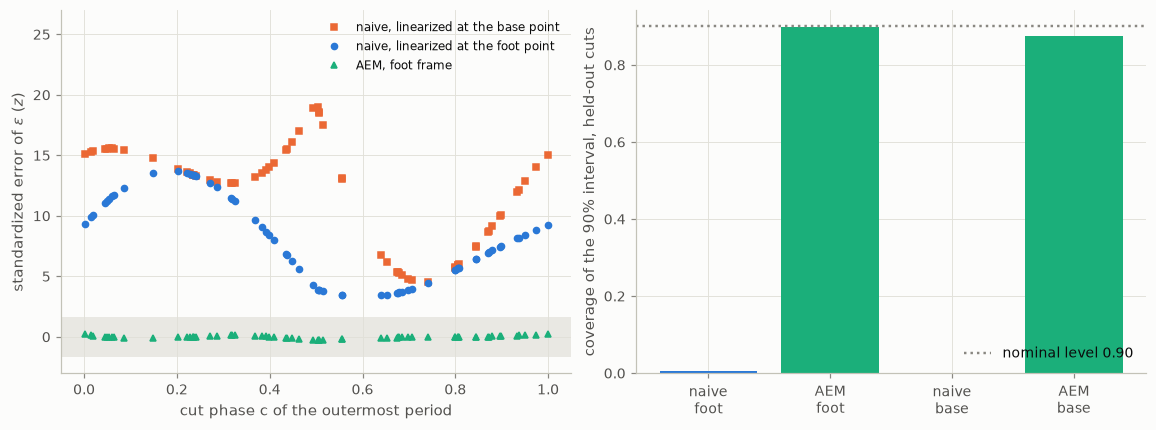

In [27]:
order = np.argsort(cuts)
fig, ax = plt.subplots(1, 2, figsize=(10.4, 3.8))
cc = cuts[order]
ax[0].plot(cc, [out["base"]["z_naive"][i] for i in order], "s", color=CAT[1], ms=4, label="naive, linearized at the base point")
ax[0].plot(cc, [out["foot"]["z_naive"][i] for i in order], "o", color=CAT[0], ms=4, label="naive, linearized at the foot point")
ax[0].plot(cc, [out["foot"]["z_aem"][i] for i in order], "^", color=CAT[2], ms=4, label="AEM, foot frame")
ax[0].axhspan(-Z90, Z90, color=GRID, alpha=0.7, lw=0); ax[0].set_ylim(-3, 27); ax[0].set_xlabel("cut phase c of the outermost period"); ax[0].set_ylabel(r"standardized error of $\varepsilon$ ($z$)"); ax[0].legend(fontsize=8)
ax[1].bar([0, 1, 2, 3], [out["foot"]["cov_naive_hold"], out["foot"]["cov_aem_hold"], out["base"]["cov_naive_hold"], out["base"]["cov_aem_hold"]], color=[CAT[0], CAT[2], CAT[1], CAT[2]])
ax[1].axhline(0.9, color=MUTED, ls=":", label="nominal level 0.90"); ax[1].legend(loc="lower right"); ax[1].set_xticks([0, 1, 2, 3], ["naive\nfoot", "AEM\nfoot", "naive\nbase", "AEM\nbase"]); ax[1].set_ylabel("coverage of the 90% interval, held-out cuts")
plt.show()

In [28]:
total = time.perf_counter() - T0
print(f"total run time of the notebook: {total:.1f} s (budget 170 s, 4 threads)")
check_in("run time within the 170 s budget", total, 0.0, 170.0)

total run time of the notebook: 106.8 s (budget 170 s, 4 threads)
PASS  run time within the 170 s budget: got 106.84, required in [0, 170]


## Caveats and open ends

- **Scope.** Everything is scalar TM in 2D. The TE polarization, where the normal field component is discontinuous and the dispersion has a different structure, is not treated. The Born discussion uses plane-wave sources and receivers on circles of radius 4 and 4.5 around a unit-scale object; the agreement of measured and predicted gain within 5% (side 3.5) and 2% (side 2.5) suggests this is accurate for the quantity used, but it is a prediction check, not a derivation of the near-field kernel. Direction dependence of the lattice $\varepsilon_{\rm eff}$ is computed for a square lattice only; the $O(k_0^4)$ anisotropy of lower-symmetry lattices is stated from the tensor argument, not computed.
- **What the detectability windows are.** The windows $p_{3\rm nat}$, $p_z$, $p_{\rm flag}$ are for the integer-$n_p$ mid-cut family evaluated up to $p=1/12$; at other core phases (and at $p=0.07$) $z$, $\Delta\Phi$ and the flag probability differ by factors of 1.5 or more (section 3), so no window is claimed for the structure of section 5. The "reports $\varepsilon_{\rm eff}(k_0)$, not the volume average" reading holds within about 2 sd (3.5 sd for the swapped order) only for that family; at other core phases the fit is 2.9 to 5.1 sd from $\langle\varepsilon\rangle+{\rm Rytov}$ because of the odd boundary term, whose coefficient is not derived here (its structure, linear in the contrast and from both the outer boundary and the center, follows from the integration by parts; the first-order data projection reproduces it to $4.5\times10^{-4}$ Rytov, which tests linearity and not the value). The period-cut even part ($0.74$ to $1.34$ Rytov over the structures tried) is not explained.
- **Pre-asymptotic.** The deficit of the radius shift (about $1.1p$ relative, section 3) and the $\Delta\varepsilon_{\rm fit}/{\rm Rytov}$ ratios of $1.45$ ($p=0.2$, period) and $1.22$ ($p=0.2$, mid) show that $p\ge0.1$ is not in the asymptotic regime; the scaling slopes ($2.04$ and $4.04$) are computed over $p=0.1\ldots0.0125$ and the windows from $n_p=20,40,80$ only. The windows were then checked by direct evaluation at $p=1/22,1/15,1/12$, which does not remove the dependence on the first-order law, because the flag probabilities use the linear model. The Monte Carlo (2000 draws at $p=1/15$, 400 at $p=1/12$) agrees at $p=1/15$; at $p=1/12$ the first-order prediction ($0.498$) is at the lower edge of the 99% interval of the observed $0.5625$ and the nonlinear-misfit prediction ($0.520$) is inside, so the first-order flag probability near $\Delta\Phi=147$ is slightly low.
- **Tolerances set after seeing results.** Section 1: the first-shell closed form ($10^{-10}$, a priori) is the only reference-free tolerance; the truncation-ratio window $[7.5,8.5]$ (8 predicted; set after a preliminary run that gave $7.90$), the isotropy ($10^{-4}$, observed $1.8\times10^{-5}$), the PWE coefficient ($10^{-3}$, observed $1.4\times10^{-4}$ and $1.55\times10^{-4}$), the $\cos4\phi$ growth window $[3.5,5]$ (4 predicted, observed $4.4$), the $22.5^\circ$ window ($10^{-2}$, observed $10^{-5}$), and the roundoff caveat at $Ka=0.05$. Section 2: the leakage window $[10^{-2},3\times10^{-2}]$, the spread of the measured/predicted ratio (15%), the convergence tolerance ($10^{-2}$, restricted to $\kappa_g\le2.5$ after seeing that the gain at 3.5 and 4 is not converged between $n=48$ and $64$), the hard-edge factor (10) and the $n=64$ against $128$ agreement window (10%, observed 7.9%). Section 3: the base-point overshoot window ($30$ to $300$), the first-order-versus-nonlinear tolerances ($5\%$ and $10\%$, far above the observed $0.16\%$ and $0.9\%$), the deficit fit ($a\in[0.9,1.4]$, residual below 5%, observed $1.12$ and $0.7\%$), the standardized-error windows (below $2.1$ for the integer family, observed $1.99$ and $2.03$; $[3,4]$ at $p=1/12$ swapped, observed $3.53$; above 3 for the four non-integer structures, observed minimum $3.36$), the even-part windows (within $1\%$ for the base structure and $0.5\%$ for all eleven, observed $0.29\%$; the factor $3$ to $5$ per halving of $p$, observed $3.9$), the odd-part windows (spread over the core phase above $0.3$, observed $0.44$; extremes below $-0.2$ and above $+0.5$, observed $-0.66$ and $+0.71$), the linearization tolerance ($2\times10^{-3}$ Rytov, observed $4.5\times10^{-4}$), the period-cut windows ($[0.70,0.78]$, spread above $0.3$), the half/full ratios within 1%, and the power check of the Monte Carlo (half-width below half the probability). The Monte Carlo itself uses an exact 99% binomial interval and sizes ($2000$, $400$) fixed before the run. Section 4: the sector tolerances are $10^{-8}$ (observed values are smaller by 3 to 7 orders), the displaced-start tolerance $10^{-6}$ sd (observed $\le7\times10^{-11}$), the forward-solver comparison of the two-layer ring (ratio to the grid floor $\le1.5$, observed $0.64$). Section 5: the foot-point tolerance of $0.1$ sd was set in PLAN.md before the computation; the thresholds of the split tests (rms $z$ below a third of the naive value, median below 1, coverage at least $0.7$, no transfer to other periods below $0.5$, 4 cuts within $0.01$) were set after a preliminary run of the same splits and sit between the observed values. A priori: the 1D tolerance, the slopes, the termination ratio $0.05$, the law identity, the ordering, the independent multilayer recursion tolerance ($10^{-9}$, observed $6\times10^{-14}$).
- **Not done.** The second-order bias of DESIGN 15.1 (curvature of the model) is not used: at $z\sim10^2$ in section 4 it would matter, and the nonlinear fits replace it. No convergence study in $n$ for the lattice forward solves beyond the floor ($n=128$ only); the floor is the homogeneous disk's, not the lattice's own discretization error. The AEM uses one structural parameter; its transfer is tested across the cut interval, two periods and one contrast change (it fails for the last two), and not across other cut families; no posterior sampling. The Born knee is verified for one grating orientation. The two-layer ring against the forward solver is one comparison at one grid, at the level of the grid floor; the multilayer series is otherwise validated by the independent recursion at $n_p=5$ and $20$ only (orders 0 to 26), not at $n_p=80$.
- **Open items.** (i) The coefficient of the odd boundary term (outer boundary and center) is not derived; only its symmetry, scaling and first-order character are shown. (ii) The period-cut even part is not explained; it is a $\Delta\chi^2p^2$ effect of the $O(p)$ termination by symmetry, depends on $R_D$ and the mean, and is not shown to be second order in the shift only. (iii) The linearization at the foot point is checked by four cuts and not proved for the ensemble. (iv) The notebook has had one independent review, whose corrections are recorded in PLAN.md; no second review has been run.
- **Design record.** `PLAN.md` records the design, the expectations written before the computations, and the corrections made after an independent review.
- **Reproducibility.** The Monte Carlo uses `numpy` default generator seed 20261123, the ensemble seed 5 (and 7, 11 for the split tests); the one thread-count dependence is the GMRES forward solve at $n=128$ (the sector statements hold to $10^{-11}$ whatever the order of summation).

## References

Checked in `PLAN.md` ("Literature (verified)") unless marked.

- S. M. Rytov, Electromagnetic properties of a finely stratified medium, Sov. Phys. JETP **2** (1956) 466-475 (Zh. Eksp. Teor. Fiz. **29** (1955) 605-616); the ordinary-wave correction of section 1.
- E. Wolf, Three-dimensional structure determination of semi-transparent objects from holographic data, Opt. Commun. **1** (1969) 153-156; the Ewald-sphere limit used in section 2.
- J. Kaipio, E. Somersalo, *Statistical and Computational Inverse Problems*, Springer, 2005; and Statistical inverse problems: discretization, model reduction and inverse crimes, J. Comput. Appl. Math. **198** (2007) 493-504; the approximation-error model of section 5.
- `docs/DESIGN.md` sections 15.1 and 15.2 (this repository): the detectability law, the profile foot point and the reflection selection rule.
- Not from a reference: the integration by parts for radial objects (section 3) is derived in place (two lines); the averaging formula of section 1 is derived in place. Bensoussan-Lions-Papanicolaou and Allaire are not cited because no statement depends on them.